# 🍎 사과 품질 판별 — 로지스틱 회귀

> 사과 4,000개의 7가지 특성(크기 · 무게 · 단맛 · 아삭함 · 과즙 · 숙성도 · 산도)으로 품질(`good` / `bad`)을 판별하는 로지스틱 회귀를
> **품질 점검 → EDA → 기준선 모형 → 가정 검정(로짓 선형성) → 체크포인트 비교 → 최종 보고**의 흐름으로 수행했습니다.
> 직선만 가정한 기준선 모형은 AUC 0.824에 머물렀지만, **가정 검정에서 찾은 곡선 관계(제곱항)를 반영하자 AUC 0.868**로 올라갔습니다.
> 특히 EDA와 기준선 모형에서 모두 '무관'으로 보였던 **아삭함(`Crunchiness`)이 U자 곡선의 강한 예측 변수**로 드러났습니다.

| 항목 | 내용 |
|---|---|
| **데이터** | Apple Quality (Kaggle) · 4,000행 × 7개 특성 (결측 · 중복 없음, 값은 표준화된 점수) |
| **종속변수** | `Quality` — `good`(2,004) / `bad`(1,996), 거의 완벽한 균형 |
| **분석 질문** | ① 어떤 특성이 사과의 품질을 가르는가? ② 특성과 품질의 관계는 직선인가, 곡선인가? ③ 판별 기준(임계값)은 어떻게 정해야 하는가? |
| **주요 기법** | Welch t / Mann-Whitney U · Box-Tidwell 로짓 선형성 검정 · 제곱항 · 후진소거 · AUC · 임계값 조정 |

### 📑 목차
0. **준비** — 라이브러리, 데이터 로드, 컬럼 의미
1. **PART 1. 데이터 품질 점검** — 식별자 제거 · 자료형 · 중복 · 결측 · 기술통계
2. **PART 2. EDA** — 단변량 → 이변량(T검정) → 다변량(공선성) → 최종 변수 선택
3. **PART 3. 기준선 모형과 가정 검정** — 기준선 모형 → 로짓 선형성 진단 → 처방 루프 → 독립성
4. **PART 4. 로지스틱 회귀 모델링** — 전처리 체크포인트 비교 → 최종 모델 선택
5. **PART 5. 최종 모델 보고** — 계수 해석 · 분류 성능 · 임계값 조정
6. **📌 종합 인사이트**

> ⚙️ **사용 모듈** : `my_qtcheck` · `my_plot` · `my_stats` · `my_prep` · `my_logit` (helpers) · 데이터 로더 `jussam`

---
# 0. 준비

### (1) 라이브러리 참조

In [29]:
from jussam import load_data
from helpers import *
from IPython.display import display, Markdown

from pandas import DataFrame

### (2) 데이터 가져오기

In [30]:
origin = load_data("apple_quality")
print(f"데이터 크기 : {origin.shape}")
origin.head()

📚 이 데이터 세트는 다양한 과일 속성에 대한 정보를 담고 있어 과일의 특성을 파악하는 데 도움이 됩니다. 데이터 세트에는 과일 ID, 크기, 무게, 당도, 아삭함, 과즙량, 숙성도, 산도 및 품질과 같은 세부 정보가 포함되어 있습니다. (출처: https://www.kaggle.com/datasets/nelgiriyewithana/apple-quality)

field        description
-----------  ----------------------------------
A_id         각 과일에 대한 고유 식별자
Size         크기
Weight       무게
Sweetness    단맛 정도
Crunchiness  과일의 아삭한 식감을 나타내는 질감
Juiciness    과일의 과즙 함량 정도
Ripeness     과일이 익은 정도
Acidity      과일의 산도 수준
Quality      과일의 전반적인 품질

데이터 크기 : (4000, 9)


,A_id,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity,Quality
0,0,-3.970,-2.512,5.346,-1.012,1.845,0.330,-0.492,good
1,1,-1.195,-2.839,3.664,1.588,0.853,0.868,-0.723,good
2,2,-0.292,-1.351,-1.738,-0.343,2.839,-0.038,2.622,bad
3,3,-0.657,-2.272,1.325,-0.098,3.638,-3.414,0.791,good
4,4,1.364,-1.297,-0.385,-0.553,3.031,-1.304,0.502,good


### (3) 컬럼 의미를 정리한 딕셔너리

In [31]:
column_means = {
    "A_id":         "사과 식별자",
    "Size":         "크기",
    "Weight":       "무게",
    "Sweetness":    "단맛 정도",
    "Crunchiness":  "아삭한 식감",
    "Juiciness":    "과즙 함량",
    "Ripeness":     "익은 정도",
    "Acidity":      "산도",
    "Quality":      "품질 (good / bad)",
}

---
# PART 1. 데이터 품질 점검

### (1) 변수 제거

- `A_id`는 **행마다 값이 모두 다른 식별자**이므로 분석 대상이 아니다. 여기서 제거한다.
  - 숫자로 저장되어 있어 그대로 두면 연속형 독립변수로 잘못 투입된다.

In [32]:
df0 = origin.drop(columns=["A_id"])
df0.head()

,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity,Quality
0,-3.970,-2.512,5.346,-1.012,1.845,0.330,-0.492,good
1,-1.195,-2.839,3.664,1.588,0.853,0.868,-0.723,good
2,-0.292,-1.351,-1.738,-0.343,2.839,-0.038,2.622,bad
3,-0.657,-2.272,1.325,-0.098,3.638,-3.414,0.791,good
4,1.364,-1.297,-0.385,-0.553,3.031,-1.304,0.502,good


### (2) 자료형 변환

- 종속변수 `Quality`는 문자열이므로 **명목형(category)** 으로 변환한다.

In [33]:
df1 = my_qtcheck.set_type(data=df0, as_category=["Quality"])

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   Size         4000 non-null   float32 
 1   Weight       4000 non-null   float32 
 2   Sweetness    4000 non-null   float32 
 3   Crunchiness  4000 non-null   float32 
 4   Juiciness    4000 non-null   float32 
 5   Ripeness     4000 non-null   float32 
 6   Acidity      4000 non-null   float32 
 7   Quality      4000 non-null   category
dtypes: category(1), float32(7)
memory usage: 113.4 KB


### (3) 데이터 중복 점검

In [34]:
df2 = my_qtcheck.check_duplicates(data=df1)
df2.head()

중복된 행의 수: 0


,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity,Quality
0,-3.970,-2.512,5.346,-1.012,1.845,0.330,-0.492,good
1,-1.195,-2.839,3.664,1.588,0.853,0.868,-0.723,good
2,-0.292,-1.351,-1.738,-0.343,2.839,-0.038,2.622,bad
3,-0.657,-2.272,1.325,-0.098,3.638,-3.414,0.791,good
4,1.364,-1.297,-0.385,-0.553,3.031,-1.304,0.502,good


### (4) 결측치 점검

In [35]:
my_qtcheck.check_missing_values(data=df2)

,Missing Count,Missing Ratio (%)
Size,0,0.000
Weight,0,0.000
Sweetness,0,0.000
Crunchiness,0,0.000
Juiciness,0,0.000
Ripeness,0,0.000
Acidity,0,0.000
Quality,0,0.000


### (5) 명목형 변수 기술통계량

In [36]:
cat_desc = my_qtcheck.categorical_summary(data=df2)
cat_desc

컬럼 'Quality'의 value_counts( ):


,count
Quality,
bad,1996
good,2004


,Quality
count,4000
unique,2
top,good
freq,2004


### (6) 연속형 변수 기술통계량

In [37]:
num_desc = my_qtcheck.numerical_summary(df2)
num_desc.T

,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity
count,4000.000,4000.000,4000.000,4000.000,4000.000,4000.000,4000.000
mean,-0.503,-0.990,-0.470,0.985,0.512,0.498,0.077
std,1.928,1.603,1.943,1.403,1.930,1.874,2.110
min,-7.152,-7.150,-6.894,-6.055,-5.962,-5.865,-7.011
25%,-1.817,-2.012,-1.738,0.063,-0.801,-0.772,-1.377
50%,-0.514,-0.985,-0.505,0.998,0.534,0.503,0.023
75%,0.806,0.031,0.802,1.894,1.836,1.766,1.510
max,6.406,5.791,6.375,7.620,7.364,7.238,7.405
rel_diff,-0.021,-0.005,-0.068,0.013,0.041,0.010,2.400
rdiff_flag,similar,similar,similar,similar,similar,similar,large_diff


>##### [💡 인사이트 — 품질 점검 결과]
>
>| 점검 항목 | 결과 |
>|---|---|
>| 관측치 수 | 4,000건 (중복 0건, 결측 0건) |
>| 식별자 | `A_id` 제거 |
>| 종속변수 | `Quality` — `good` 2,004건 / `bad` 1,996건 |
>| 연속형 독립변수 | 7종 (`Size` ~ `Acidity`) |
>| 왜도 | 7종 **모두 `symmetric`** (\|왜도\| < 0.15) → 로그변환 대상 없음 |
>| 이상치 | 7종 모두 **1.3% 이하** → 대체 여부는 뒤에서 체크포인트로 비교 |
>
>- 값의 범위가 대략 −7 ~ +7이고 평균이 0 부근이다. **원 단위가 아니라 이미 표준화된 지표**로 제공된 데이터다.
>   - 따라서 "크기 1 증가"는 mm나 g가 아니라 **표준화 점수 1점 증가**로 읽어야 한다.
>- 종속변수가 **2,004 : 1,996으로 거의 완벽하게 균형**이다.
>   - 정확도(Accuracy)의 함정(불균형 데이터에서 게으른 모형이 높은 점수를 받는 문제)이 **이 데이터에서는 발생하지 않는다.**

---
# PART 2. 탐색적 데이터분석(EDA)

### (1) 변수 유형 분류

- `target_is_continuous`는 `False`로 바꾼다.

In [38]:
target = "Quality"                    # 종속변수
target_is_continuous = False          # 종속변수 연속형 여부  --> 로지스틱이므로 False
nominal_cols = my_qtcheck.get_categorical_column_names(df2)   # 명목형 변수
continuous_cols = my_qtcheck.get_number_column_names(df2)     # 연속형 변수

if target_is_continuous:
    continuous_cols.remove(target)  # 연속형 변수 이름에서 종속변수 항목 제거
else:
    nominal_cols.remove(target)     # 명목형 변수 이름에서 종속변수 항목 제거

print("종속변수 :", target)
print("종속변수 유형: " + ("연속형" if target_is_continuous else "명목형"))
print("명목형   :", nominal_cols)
print("연속형   :", continuous_cols)

종속변수 : Quality
종속변수 유형: 명목형
명목형   : []
연속형   : ['Size', 'Weight', 'Sweetness', 'Crunchiness', 'Juiciness', 'Ripeness', 'Acidity']


### (2) EDA 범위 정리

| 종속유형 | 독립유형 | 분석 유형 | 대상 변수 | 적용 여부 | 비고 |
|---|---|---|---|---|---|
| 연속형 | 연속형 | 상관분석 | — | ❌ 미적용 | 종속변수 타입이 명목형 |
| 연속형 | 명목형(2집단) | T검정 | — | ❌ 미적용 | 종속변수 타입이 명목형 |
| 연속형 | 명목형(3집단+) | ANOVA | — | ❌ 미적용 | 종속변수 타입이 명목형 |
| **명목형(2집단)** | **연속형** | **T검정** | 연속형 독립변수 7종 → `Quality` | ✅ **적용** | 이 데이터의 핵심 |
| 명목형(2집단) | 명목형(2집단) | 교차분석 | — | ❌ 미적용 | 명목형 독립변수 없음 |
| 명목형(2집단) | 명목형(3집단+) | 교차분석 | — | ❌ 미적용 | 명목형 독립변수 없음 |
| 명목형(3집단+) | 연속형 | ANOVA | — | ❌ 미적용 | 종속변수가 2집단 |
| 명목형(3집단+) | 명목형(2집단) | 교차분석 | — | ❌ 미적용 | 종속변수가 2집단 |
| 명목형(3집단+) | 명목형(3집단+) | 교차분석 | — | ❌ 미적용 | 종속변수가 2집단 |

- 종속변수 `Quality`가 **명목형 2집단**이므로 4~6행만 후보가 되고, 그 중 독립변수가 실제로 존재하는 **T검정**만 수행된다.
- **주의** — 종속변수가 명목형이면 **상관분석(피어슨·스피어만)을 쓸 수 없다.**
  상관계수는 두 변수가 모두 연속형일 때 정의되는 지표이기 때문이다.
  같은 질문("이 변수가 품질과 관련이 있는가")에 답하는 도구가 **T검정**으로 바뀐다.

## 2-1. 단변량 분석

### (1) 명목형 종속변수에 대한 단변량 분석

- 종속변수의 **범주 비율(균형 여부)** 을 본다.

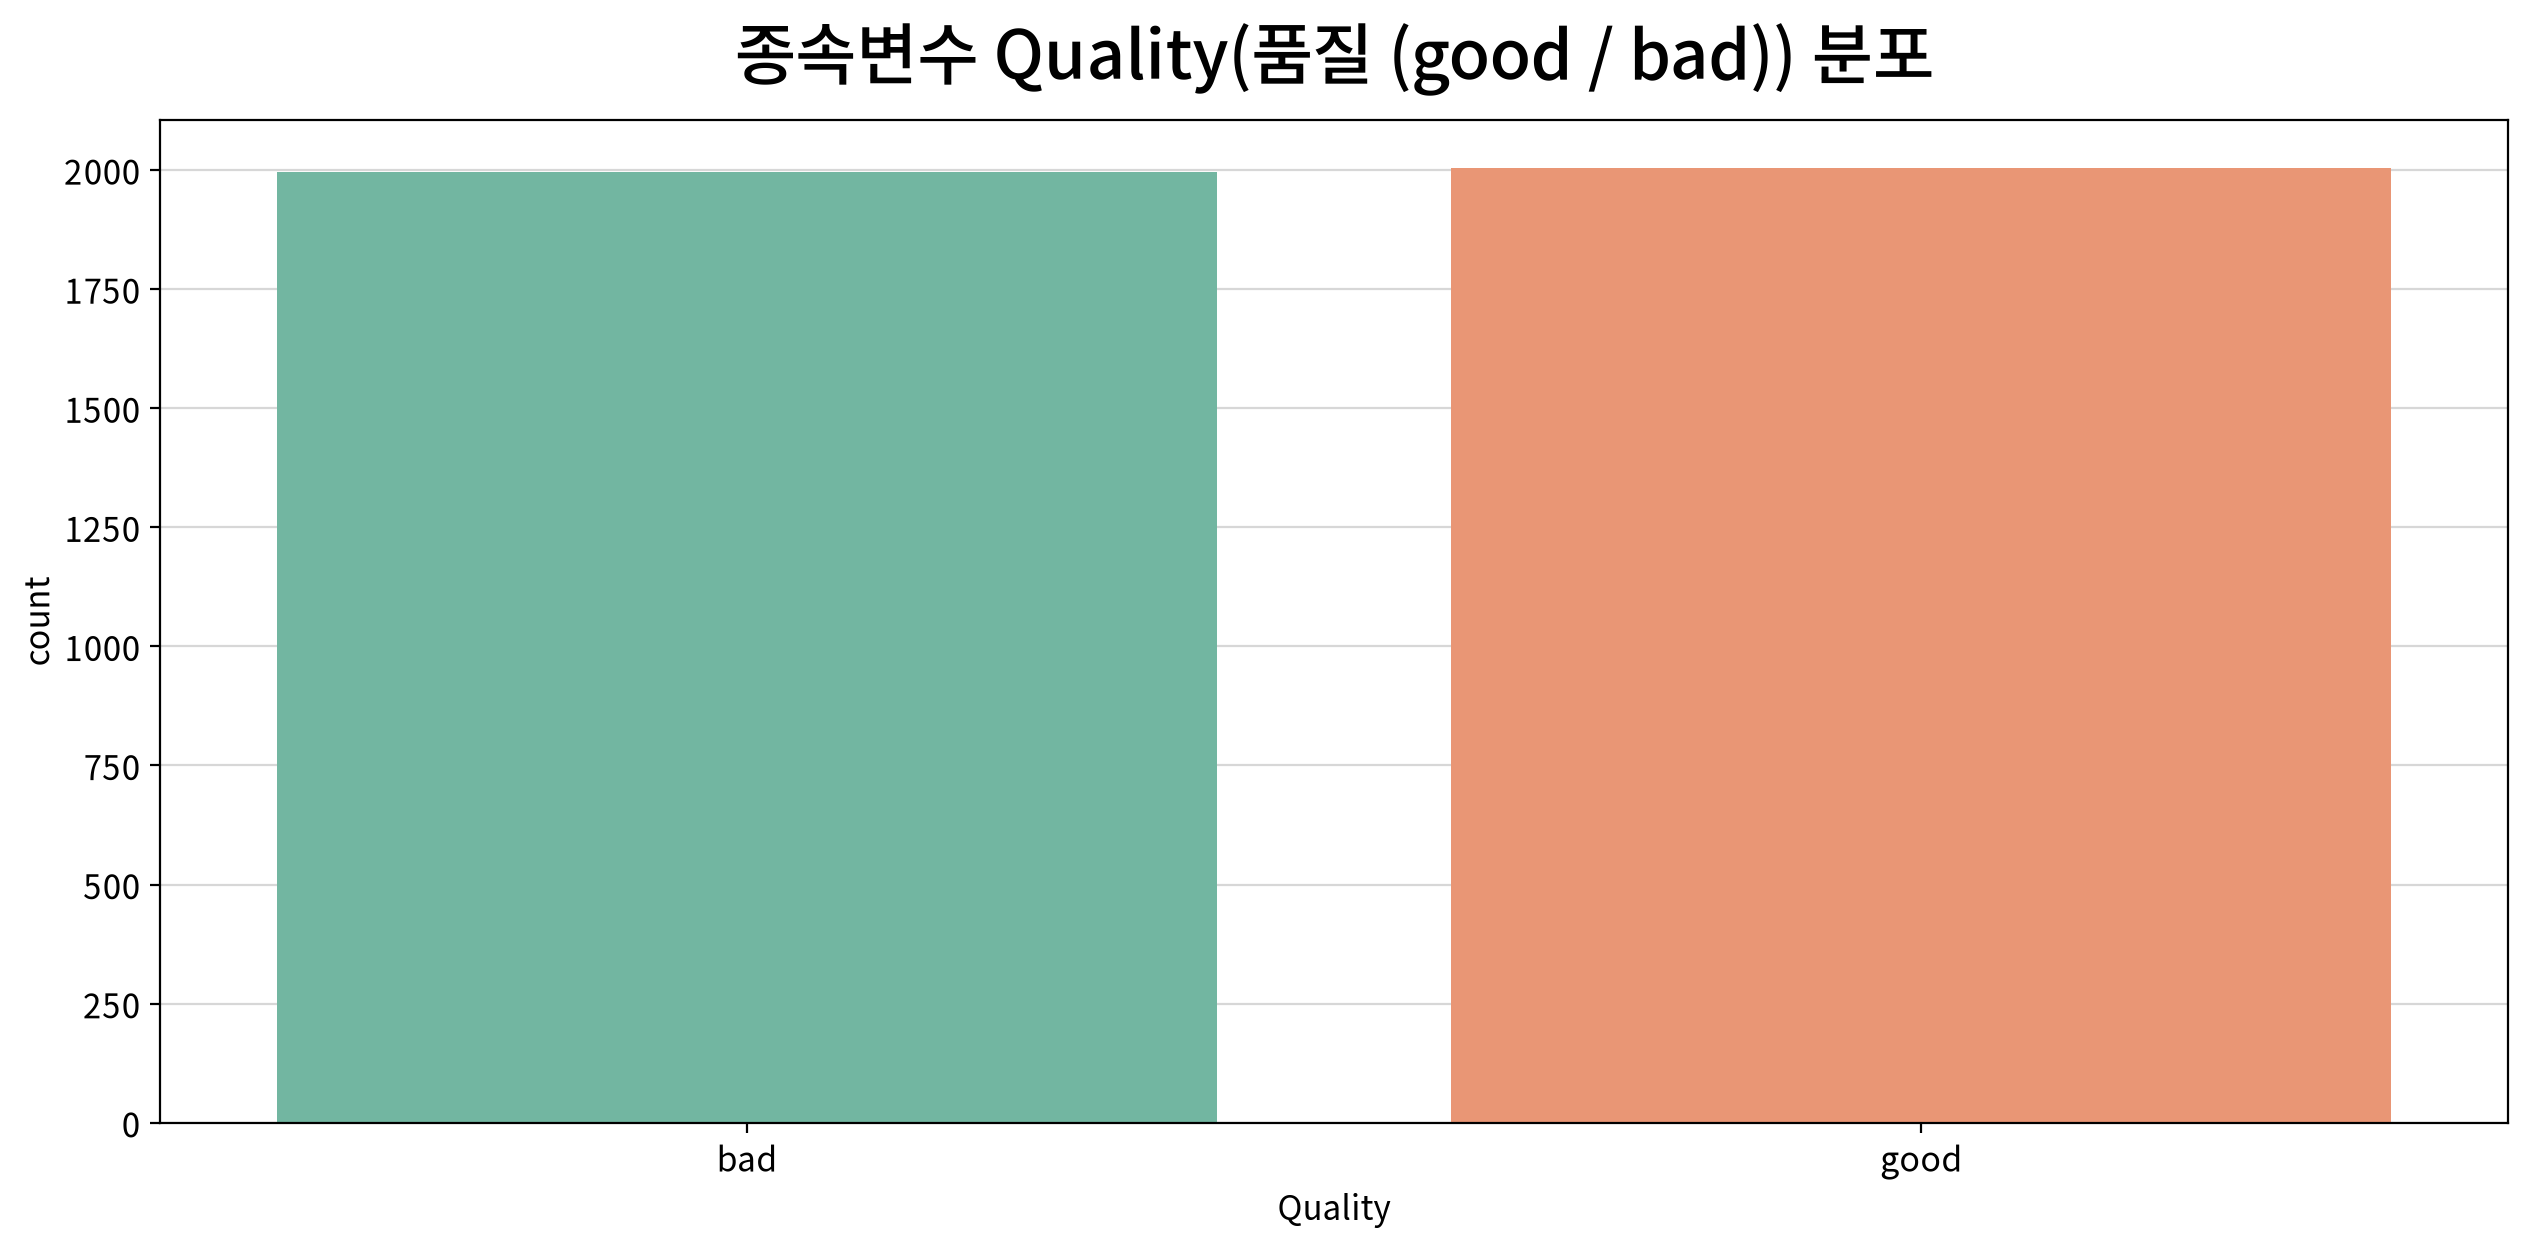

,Quality
count,4000
unique,2
top,good
freq,2004


,빈도,비율
Quality,,
good,2004,0.501
bad,1996,0.499


In [39]:
# 명목형 분포는 카운트 플롯으로 처리한다.
my_plot.countplot(data=df2, x=target, hue=target, palette="Set2",
                  title=f"종속변수 {target}({column_means[target]}) 분포")

# 명목형 기술통계량
display(cat_desc[[target]])

# 빈도표 생성
freq = df2[target].value_counts().rename("빈도").to_frame()
freq["비율"] = df2[target].value_counts(normalize=True)
display(freq)

>##### 💡 인사이트
>
>| 점검 항목 | `Quality` 관찰값 |
>|---|---|
>| 범주 수 | 2 (`good` / `bad`) → **이분형** 이므로 로지스틱 회귀 적용 가능 |
>| 최빈 범주 | `good` 2,004건 (50.1%) |
>| 최소 범주 | `bad` 1,996건 (49.9%) |
>| 균형 여부 | **거의 완벽한 균형** (차이 8건, 0.2%p) |
>
>- 균형 데이터이므로 **정확도(Accuracy)를 그대로 신뢰해도 되는 드문 경우**다.
>   - 무조건 `good`이라고만 답하는 게으른 모형의 정확도는 **50.1%** 에 그친다.
>   - 즉 정확도 50%가 이 데이터의 **바닥값(baseline)** 이고, 모형은 그보다 얼마나 올라가는지로 평가한다.

### (2) 연속형 독립변수에 대한 단변량 분석

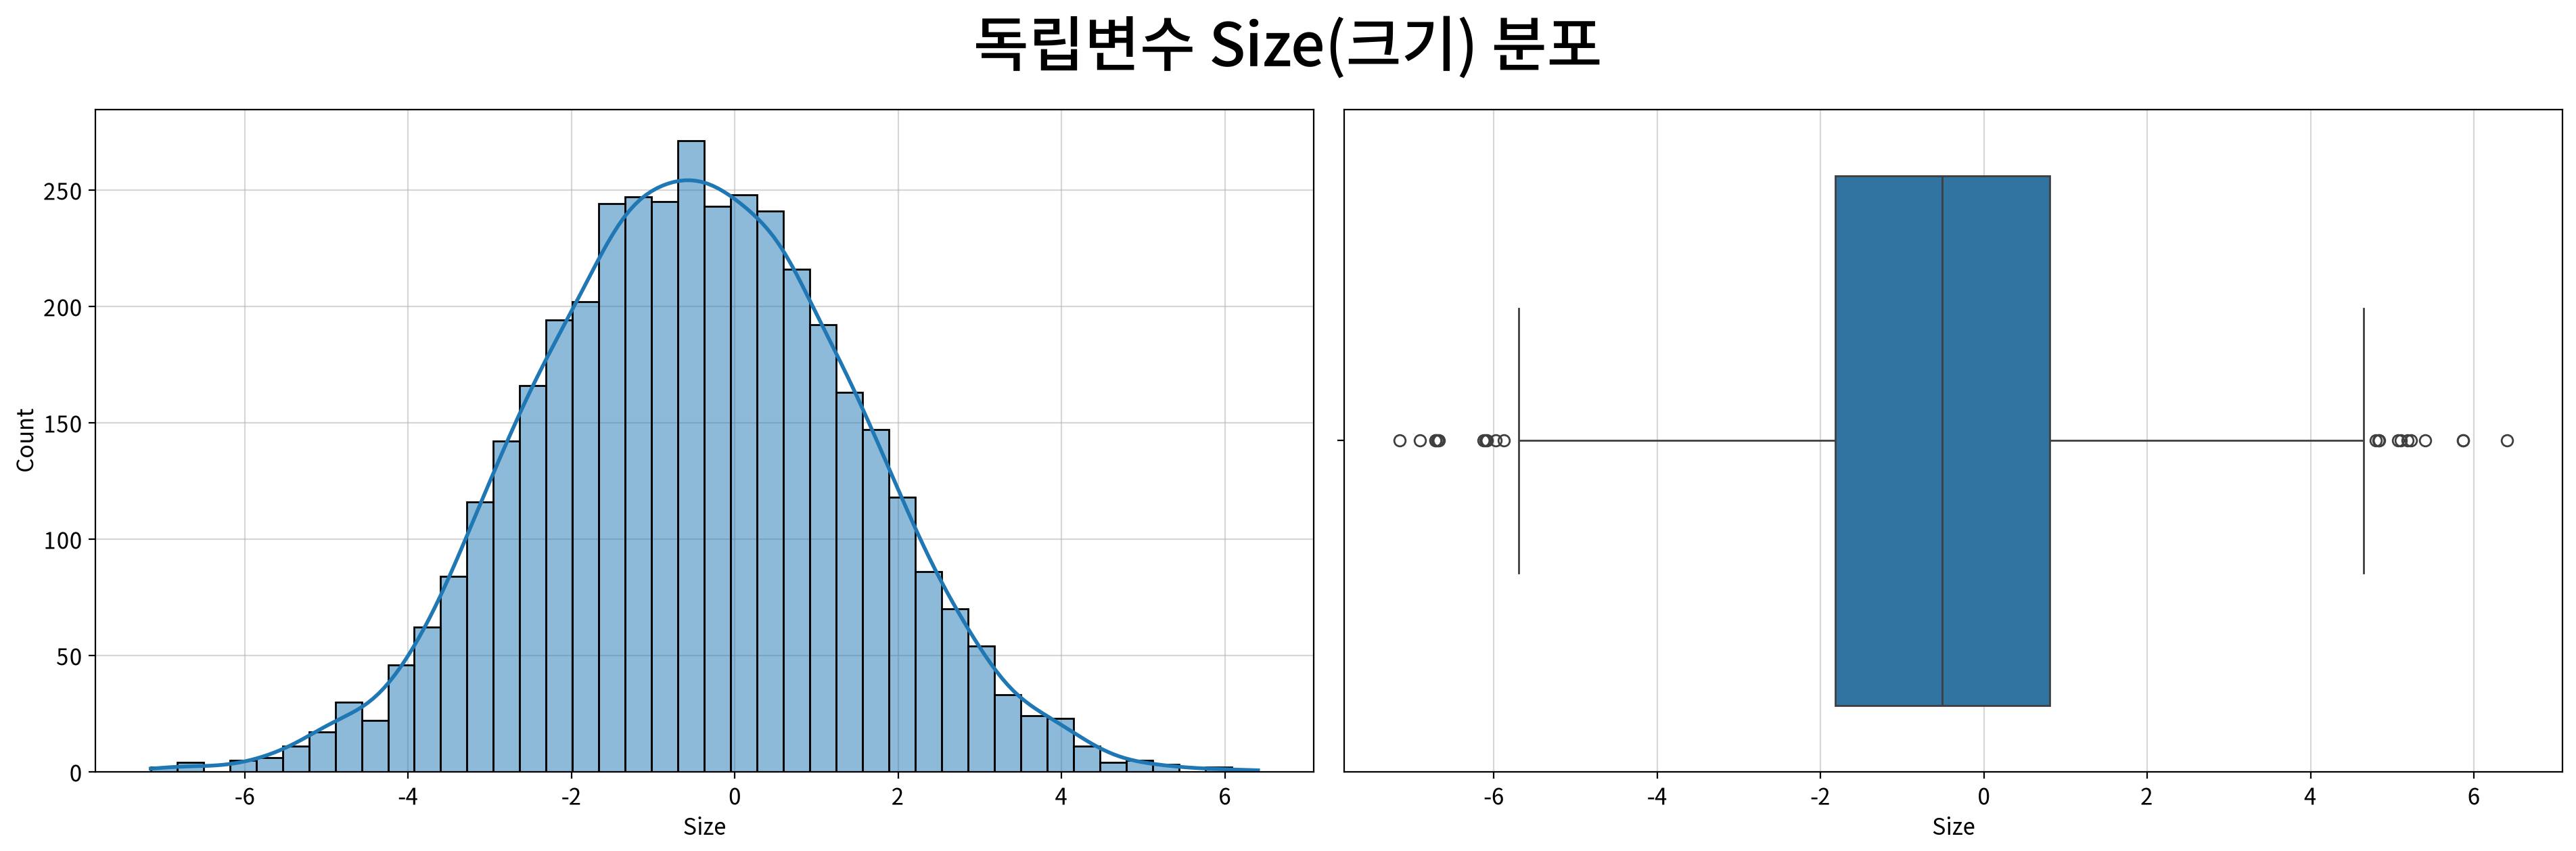

,Size
count,4000.000
mean,-0.503
std,1.928
min,-7.152
25%,-1.817
50%,-0.514
75%,0.806
max,6.406
rel_diff,-0.021
rdiff_flag,similar


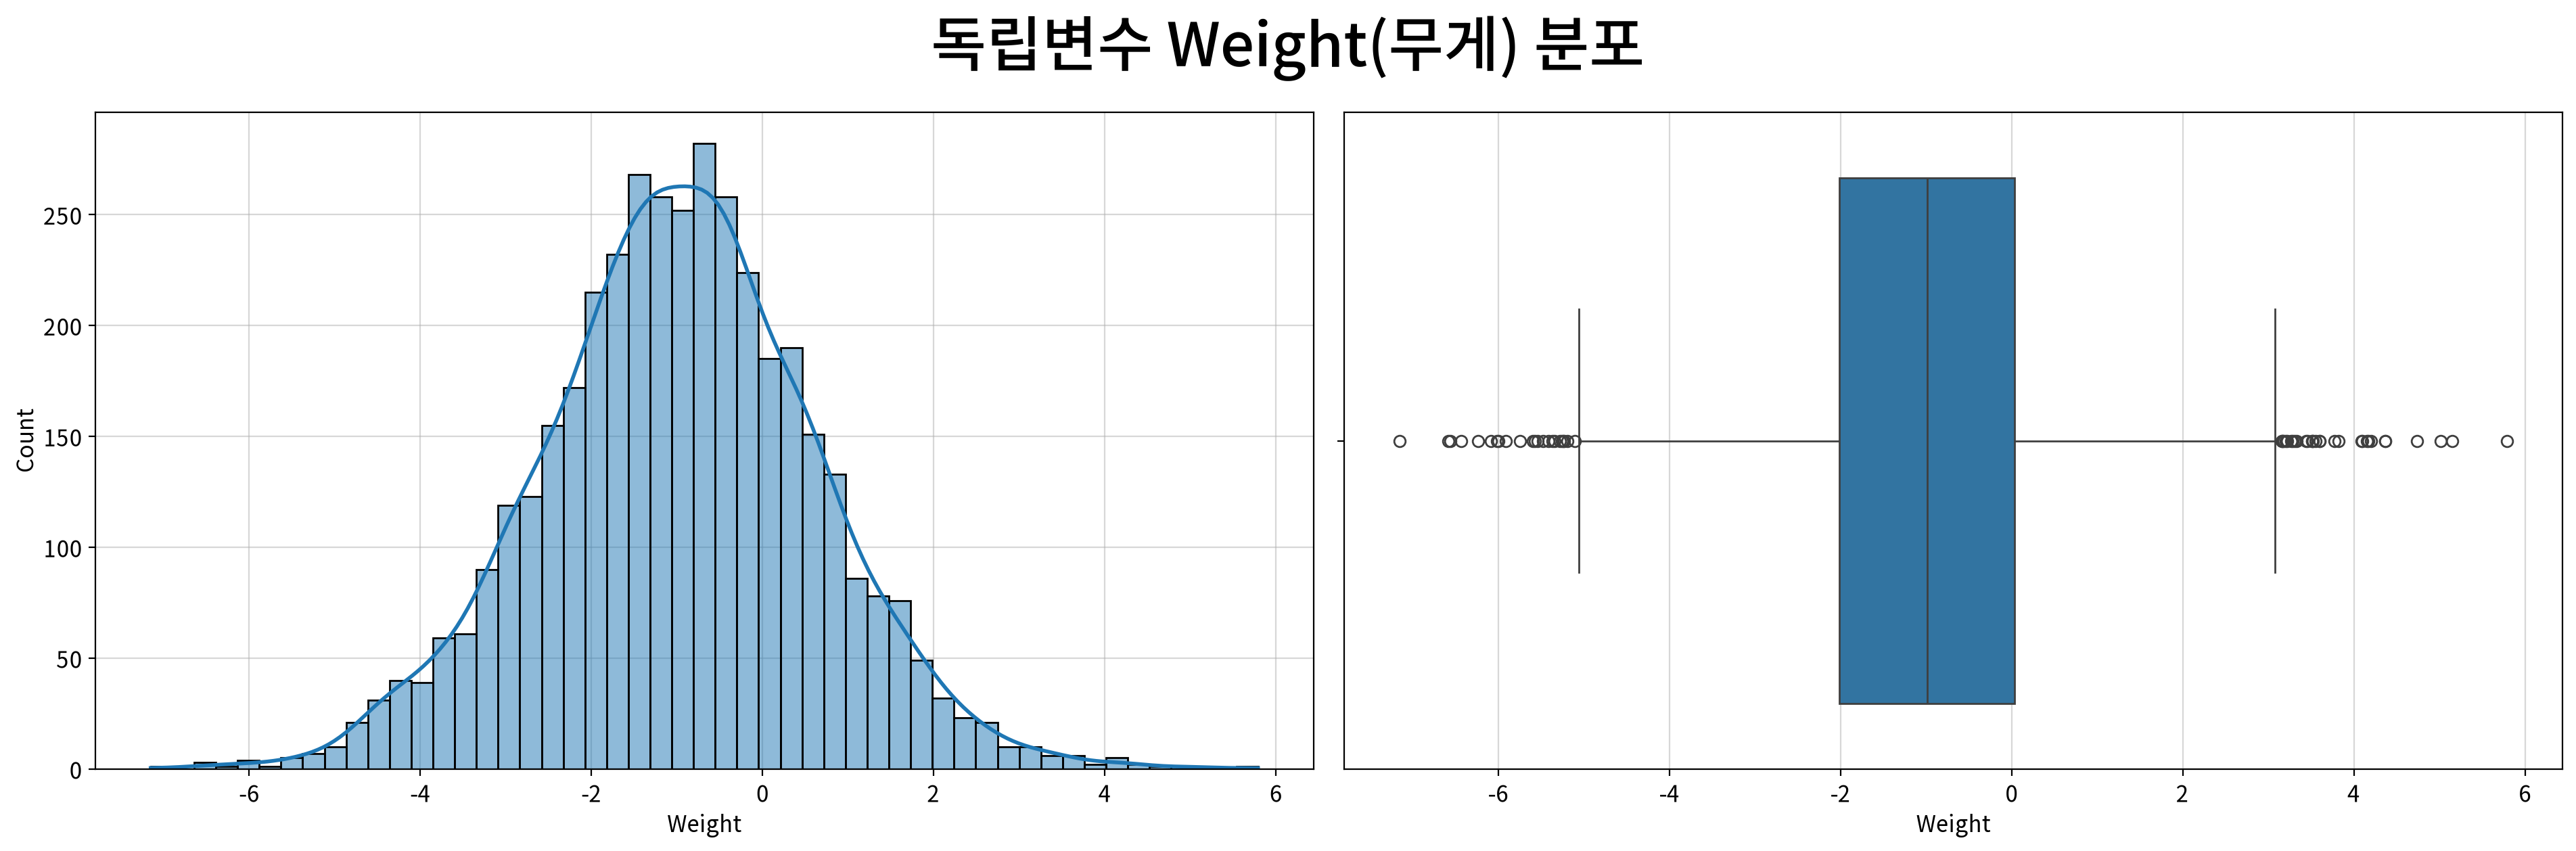

,Weight
count,4000.000
mean,-0.990
std,1.603
min,-7.150
25%,-2.012
50%,-0.985
75%,0.031
max,5.791
rel_diff,-0.005
rdiff_flag,similar


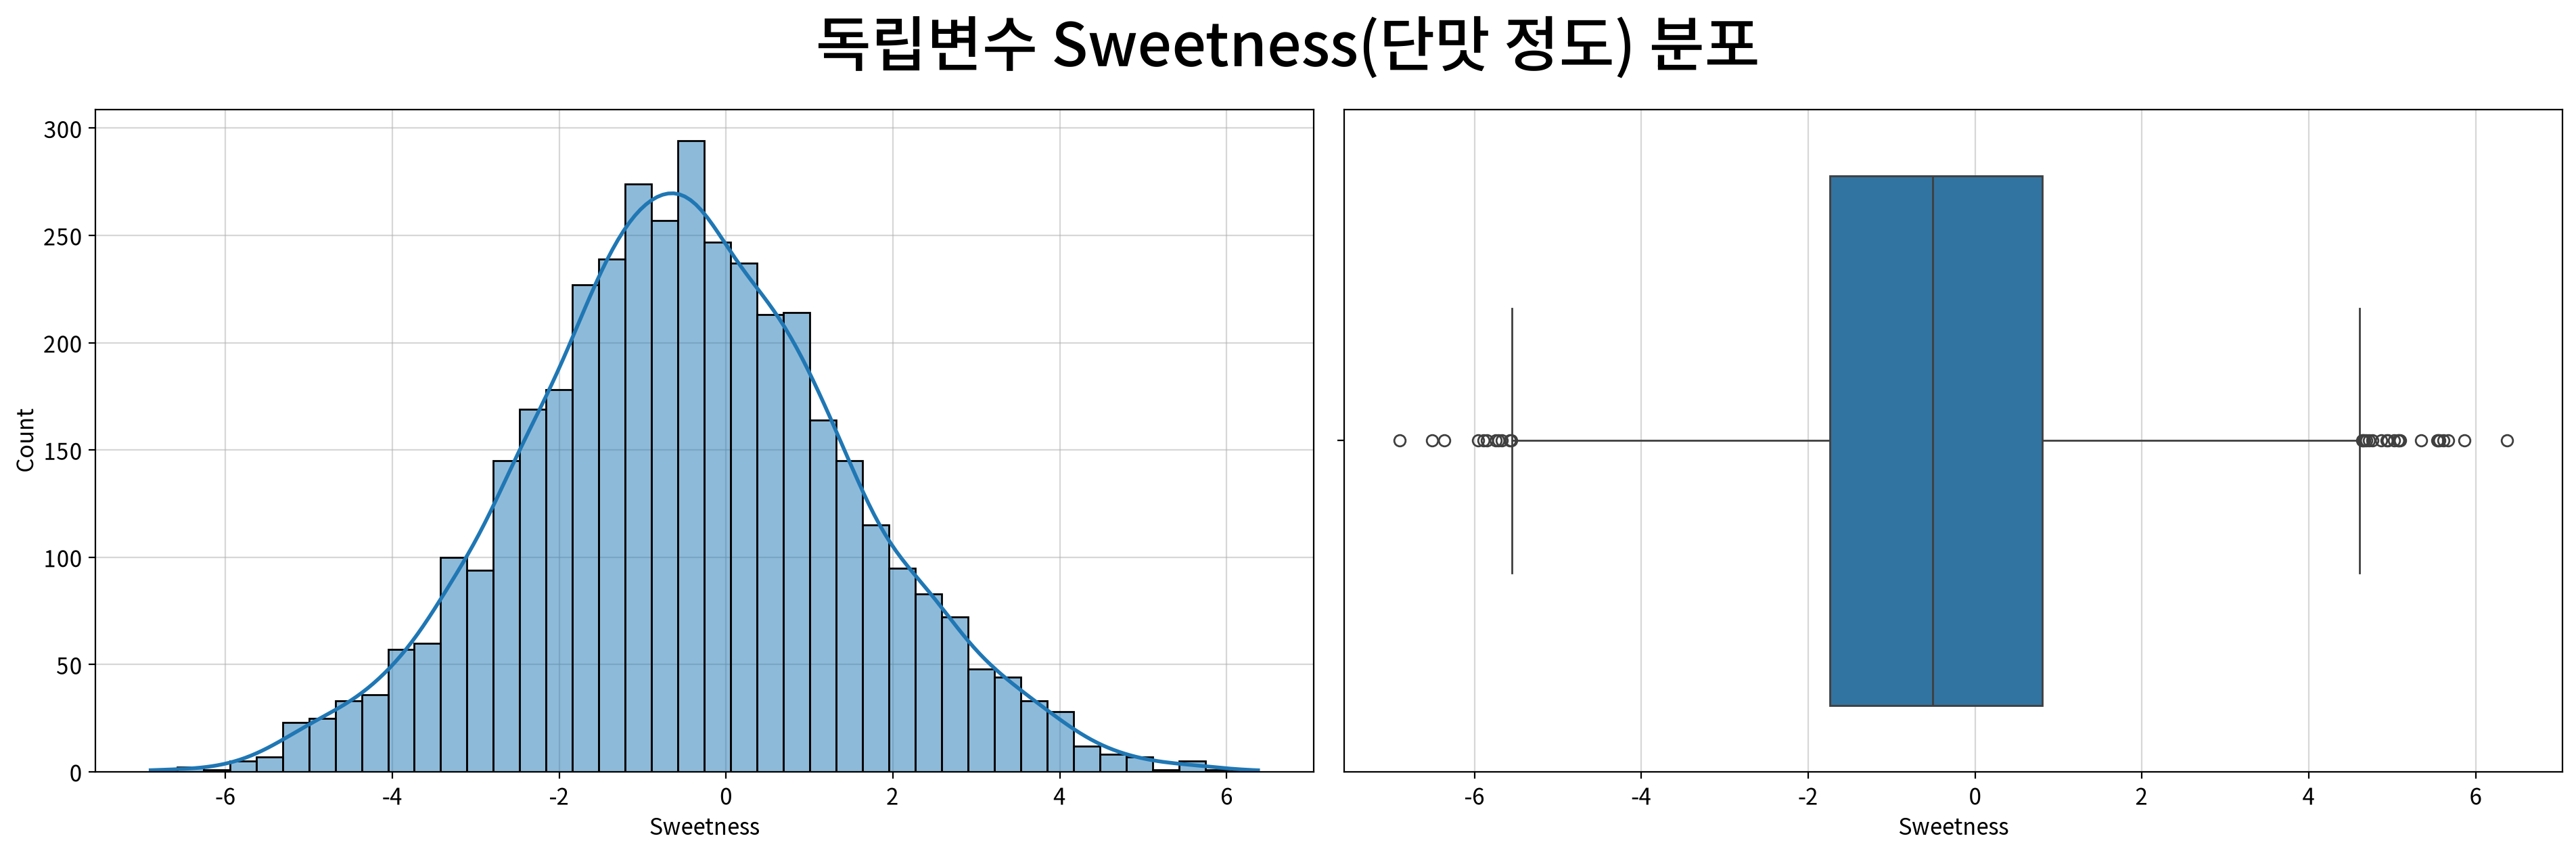

,Sweetness
count,4000.000
mean,-0.470
std,1.943
min,-6.894
25%,-1.738
50%,-0.505
75%,0.802
max,6.375
rel_diff,-0.068
rdiff_flag,similar


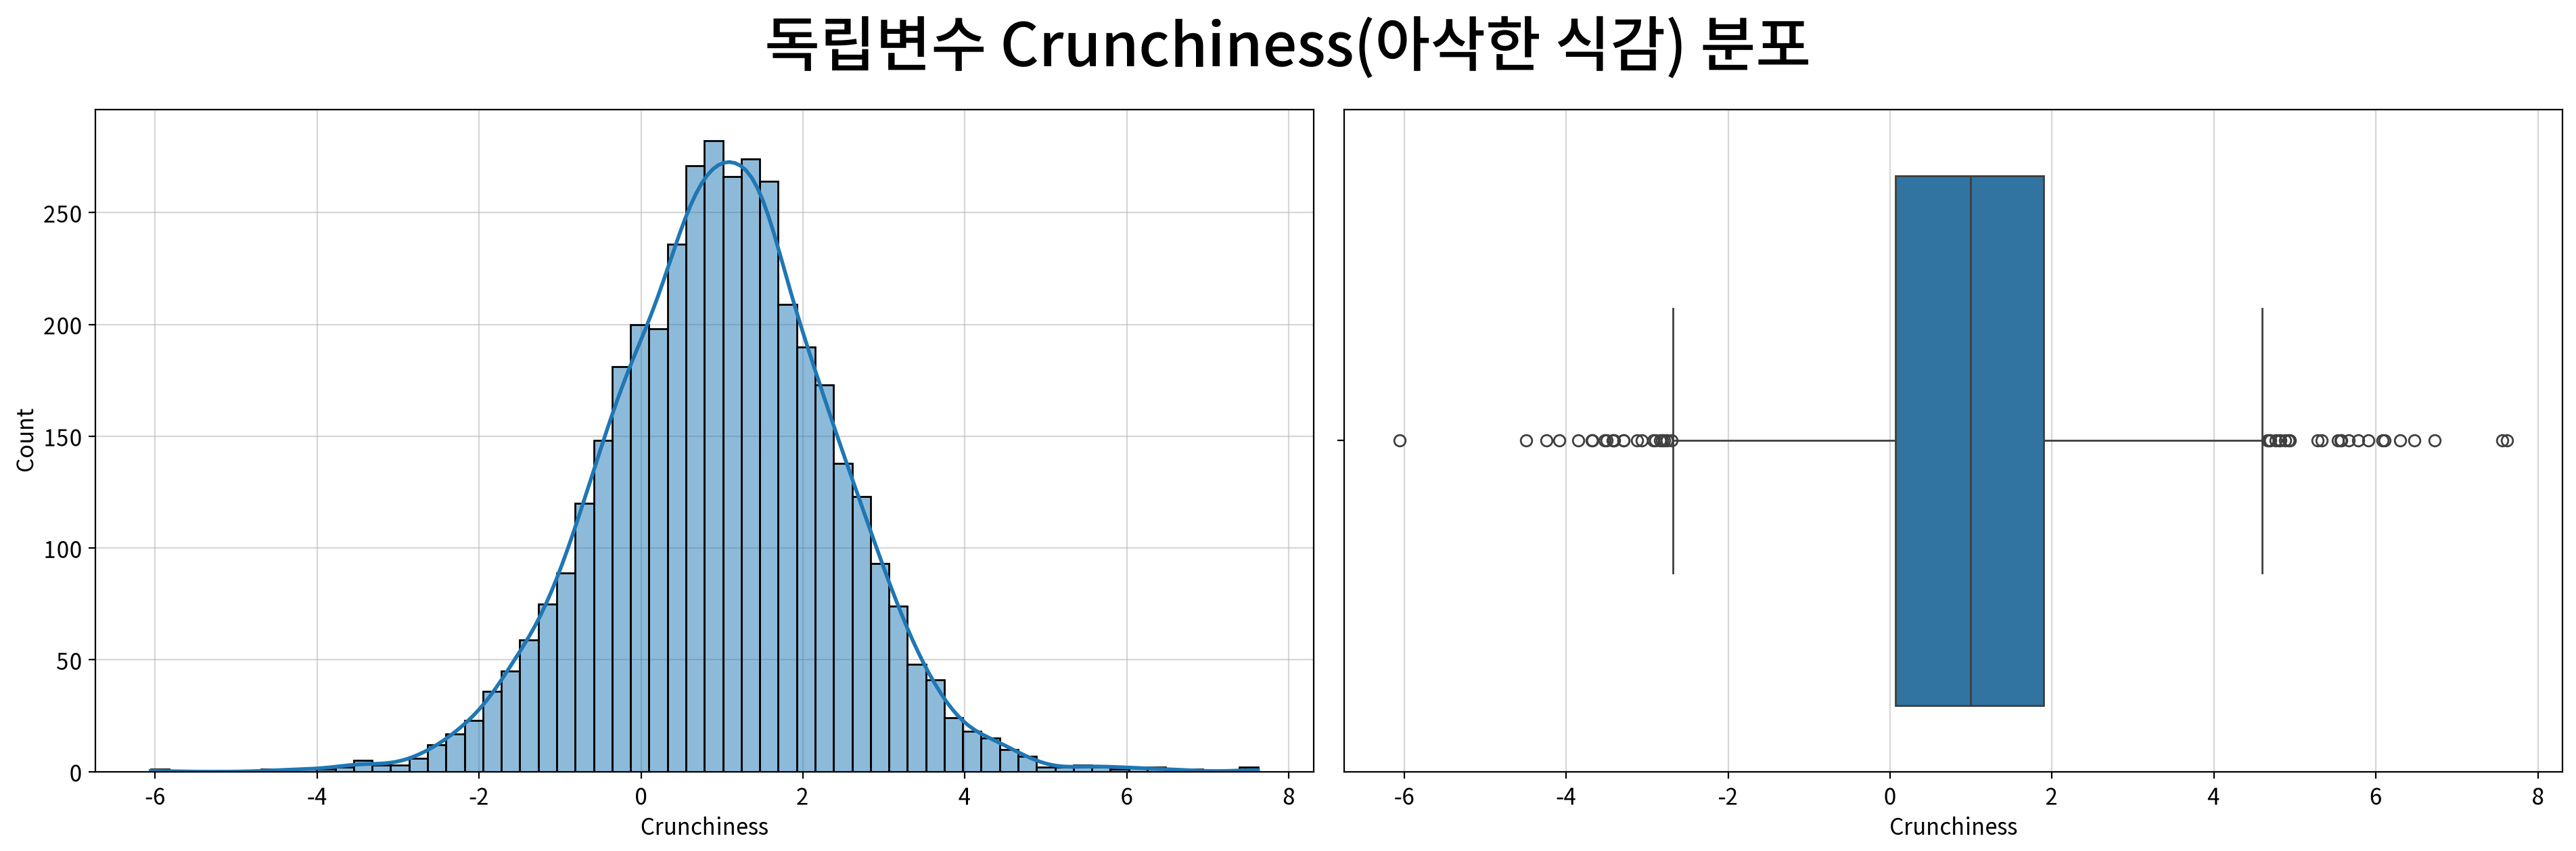

,Crunchiness
count,4000.000
mean,0.985
std,1.403
min,-6.055
25%,0.063
50%,0.998
75%,1.894
max,7.620
rel_diff,0.013
rdiff_flag,similar


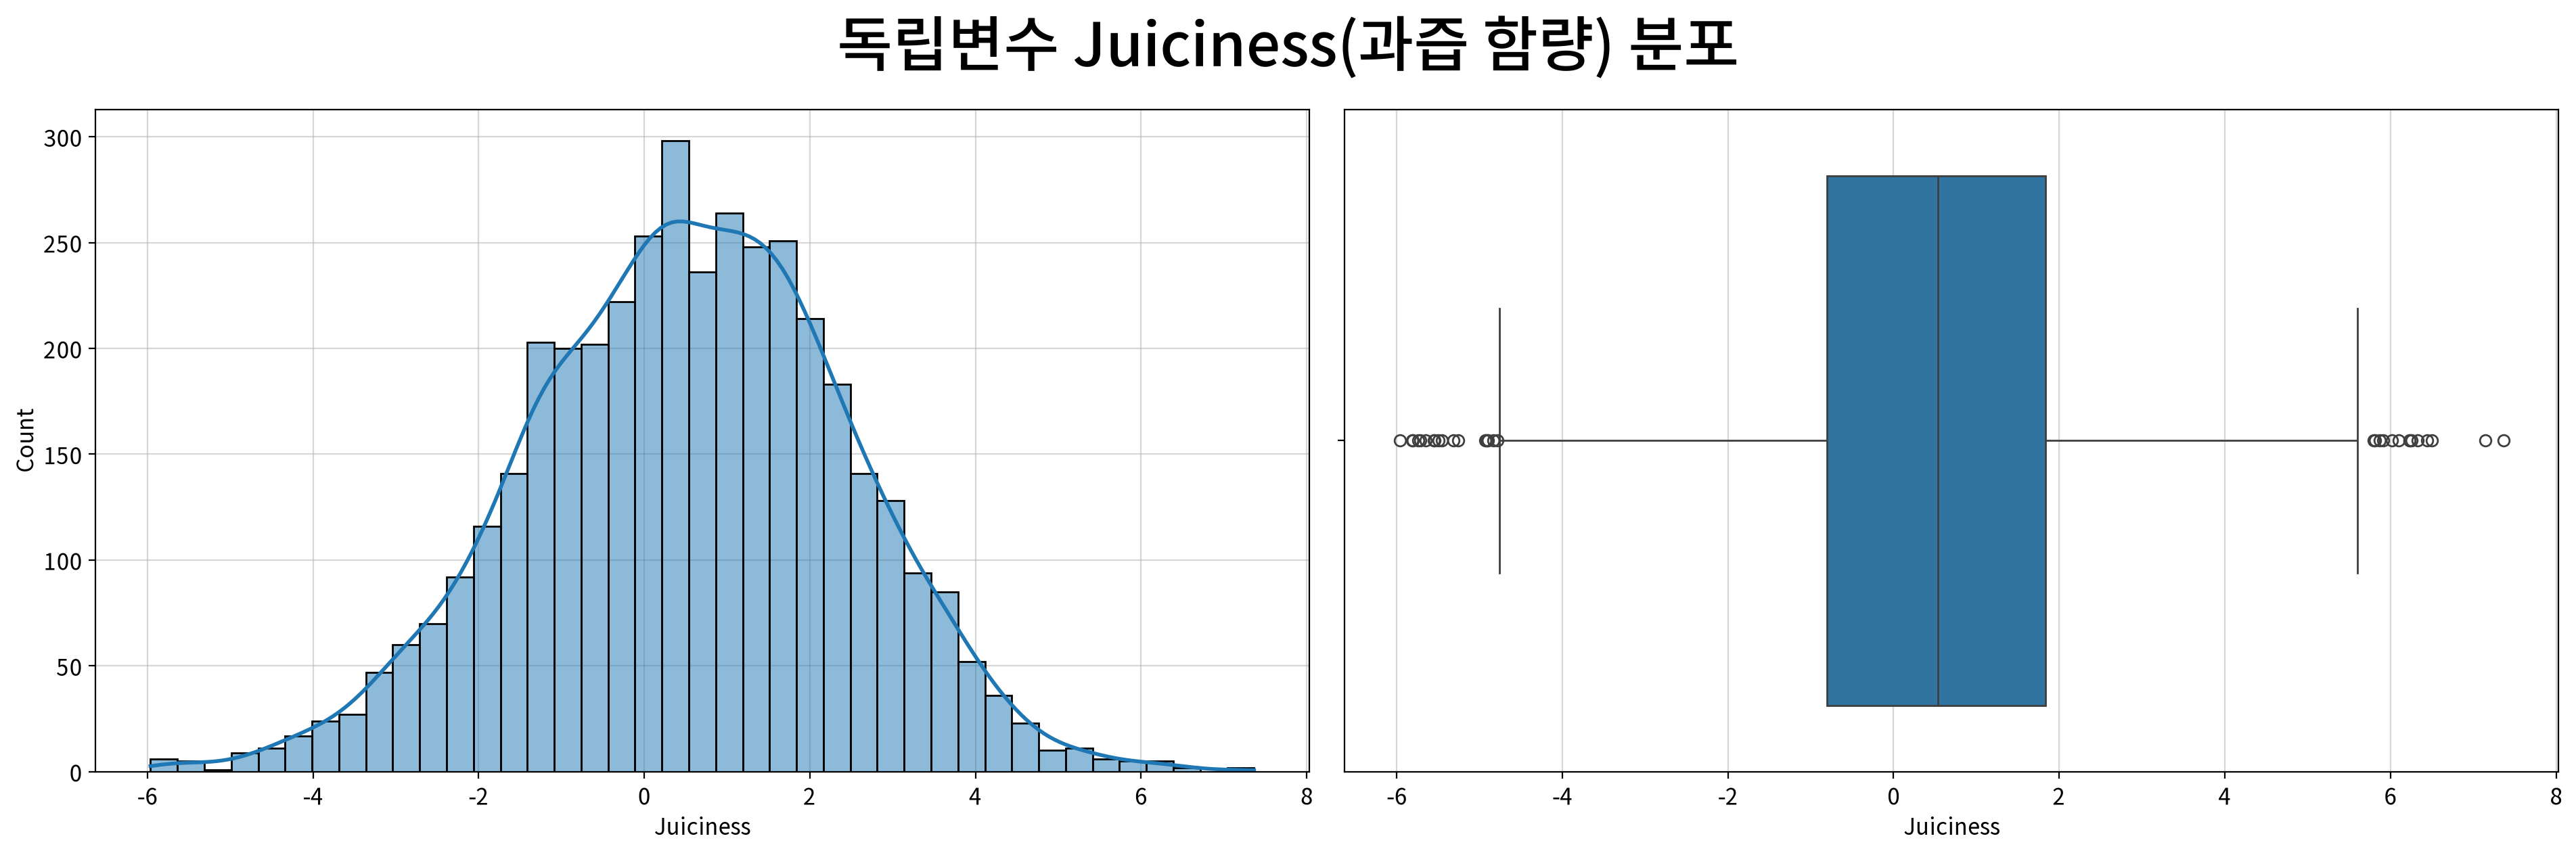

,Juiciness
count,4000.000
mean,0.512
std,1.930
min,-5.962
25%,-0.801
50%,0.534
75%,1.836
max,7.364
rel_diff,0.041
rdiff_flag,similar


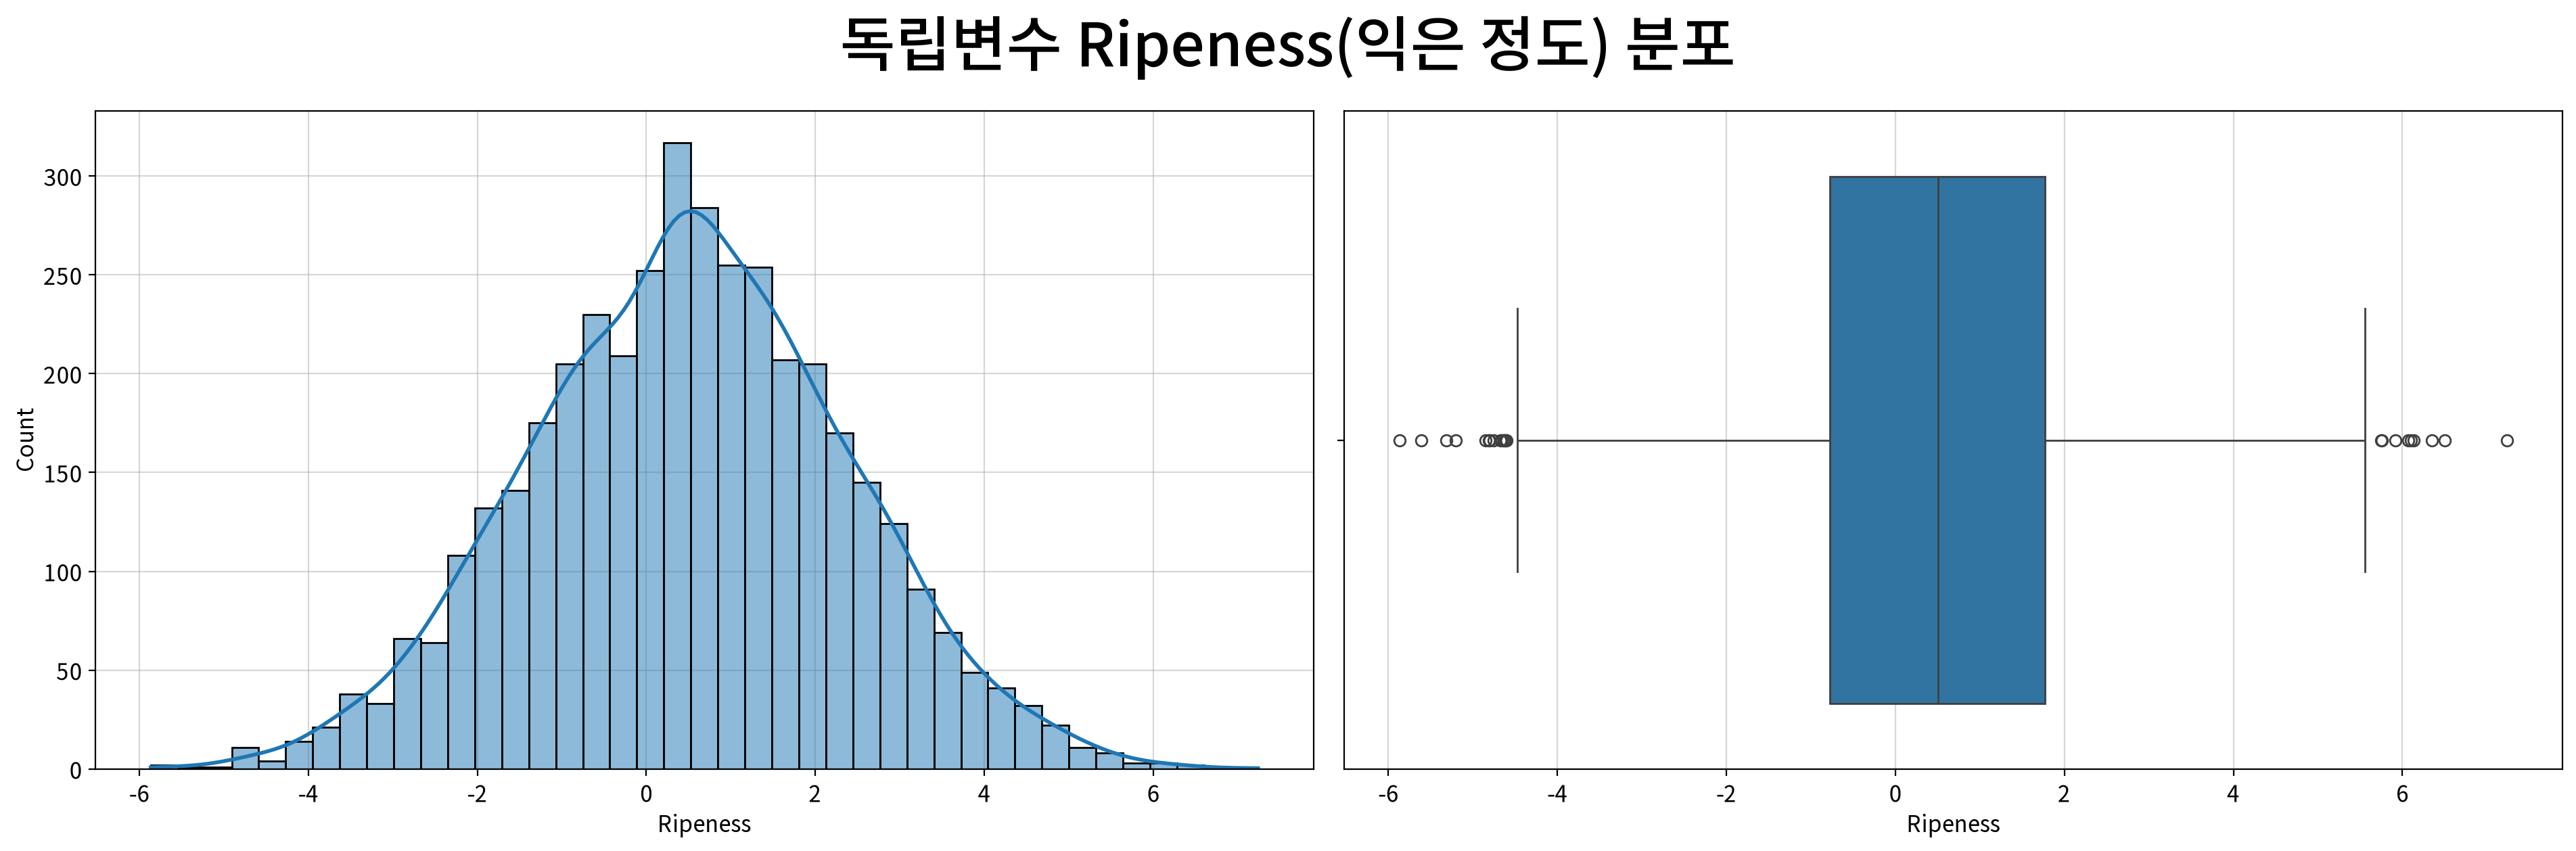

,Ripeness
count,4000.000
mean,0.498
std,1.874
min,-5.865
25%,-0.772
50%,0.503
75%,1.766
max,7.238
rel_diff,0.010
rdiff_flag,similar


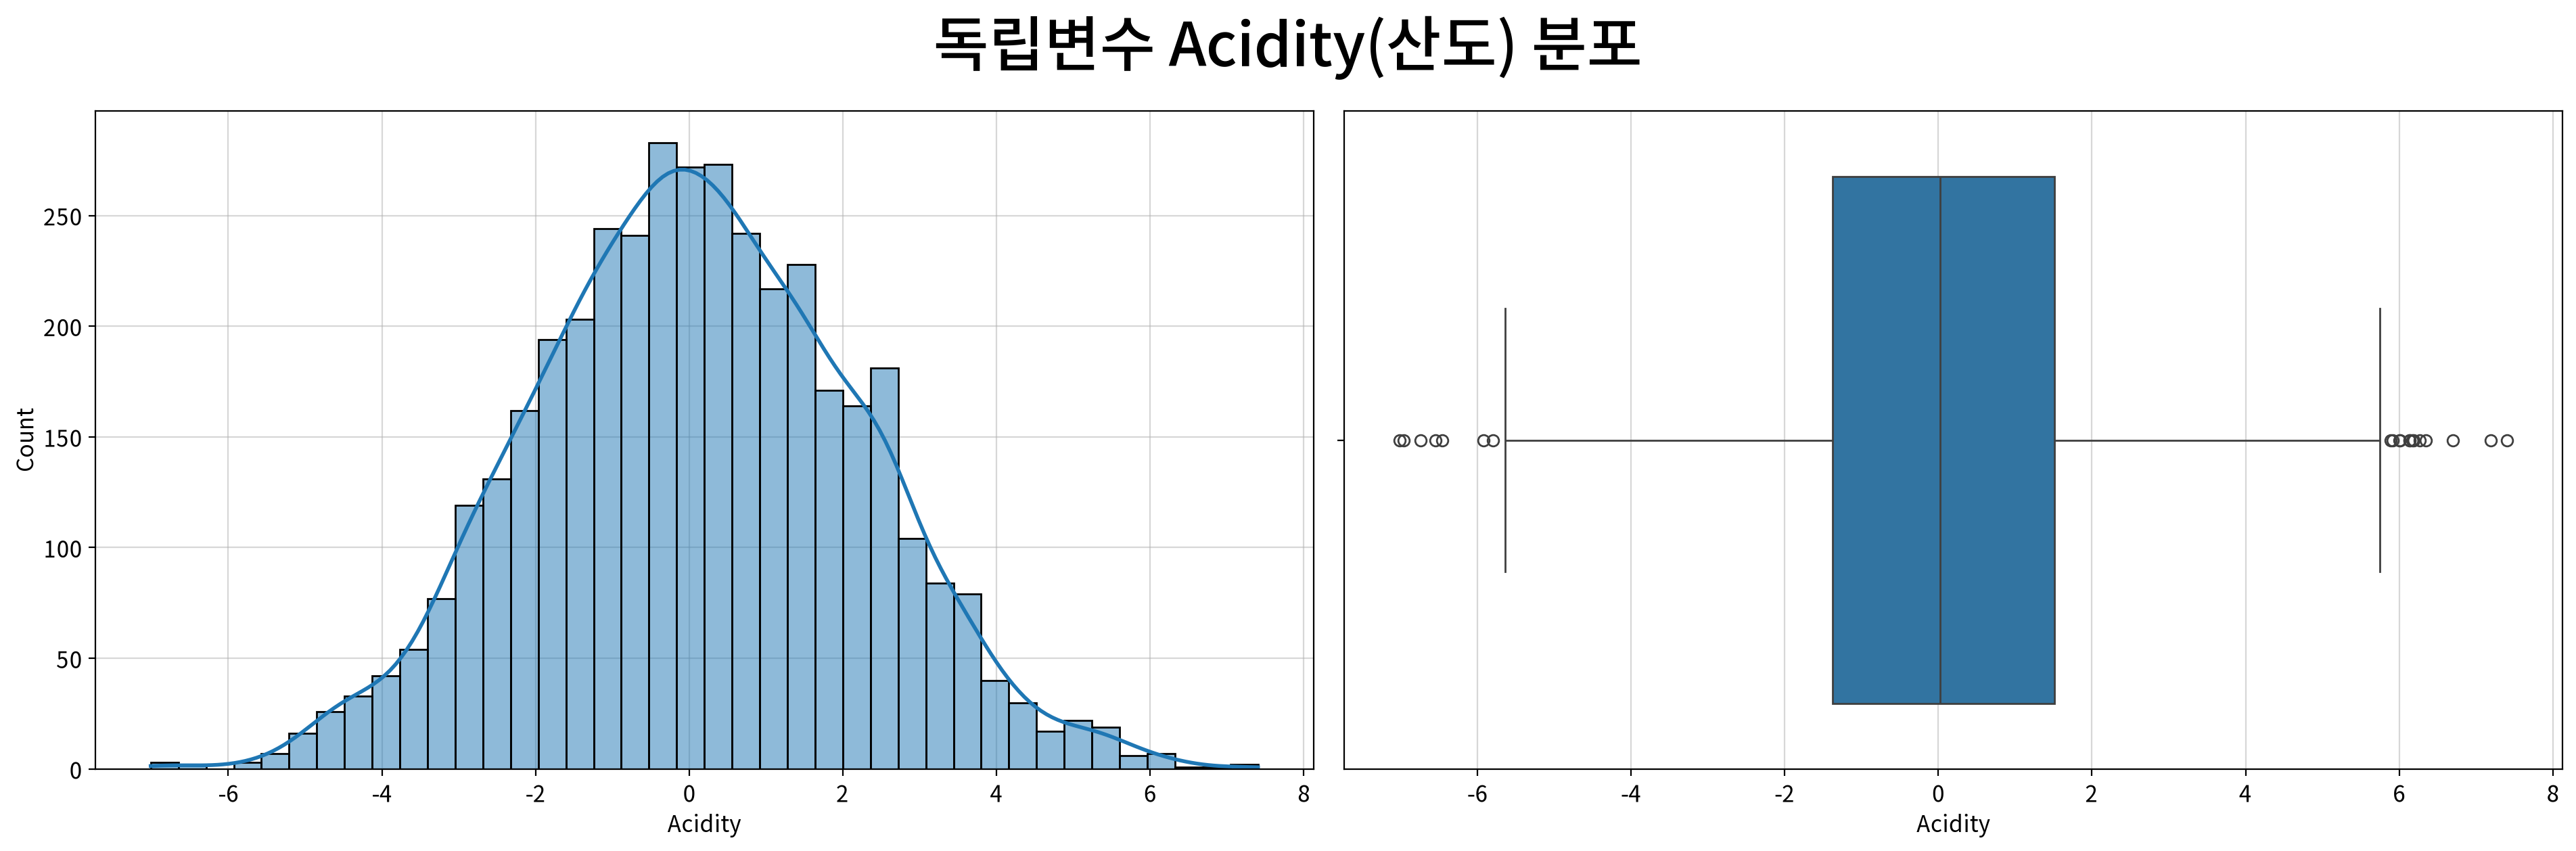

,Acidity
count,4000.000
mean,0.077
std,2.110
min,-7.011
25%,-1.377
50%,0.023
75%,1.510
max,7.405
rel_diff,2.400
rdiff_flag,large_diff


In [40]:
for f in continuous_cols:
    fig, ax = my_plot.init(rows=1, cols=2, width=960, height=640,
                           title=f"독립변수 {f}({column_means[f]}) 분포")
    my_plot.histplot(data=df2, x=f, kde=True, ax=ax[0])
    my_plot.boxplot(data=df2, x=f, ax=ax[1])
    my_plot.show()

    display(num_desc[num_desc.index == f].T)

>##### 💡 인사이트
>
>| 변수 | 분포 모양(왜도) | 봉우리 수 | 이상치 | 판단·조치 |
>|---|---|---|---|---|
>| `Size` | 대칭 (−0.002) | 단봉 | 22건 (0.5%) | 변환 불필요 |
>| `Weight` | 대칭 (+0.003) | 단봉 | 54건 (1.3%) | 변환 불필요 |
>| `Sweetness` | 대칭 (+0.084) | 단봉 | 32건 (0.8%) | 변환 불필요 |
>| `Crunchiness` | 대칭 (0.000) | 단봉 | 47건 (1.2%) | 변환 불필요 |
>| `Juiciness` | 대칭 (−0.113) | 단봉 | 32건 (0.8%) | 변환 불필요 |
>| `Ripeness` | 대칭 (−0.009) | 단봉 | 24건 (0.6%) | 변환 불필요 |
>| `Acidity` | 대칭 (+0.056) | 단봉 | 20건 (0.5%) | 변환 불필요 |

## 2-2. 이변량 분석

### (1) T-Test (x: 연속형 독립변수 → y: 2집단 명목형 종속변수)

- 선형회귀에서 **상관분석**이 하던 역할("이 독립변수가 종속변수와 관련이 있는가")을
  로지스틱 회귀에서는 **T검정**이 맡는다.

#### ▶︎ Size(크기) → Quality

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

bad vs. good: Mann-Whitney-Wilcoxon test two-sided, P_val:0.000e+00 U_stat=1.434e+06


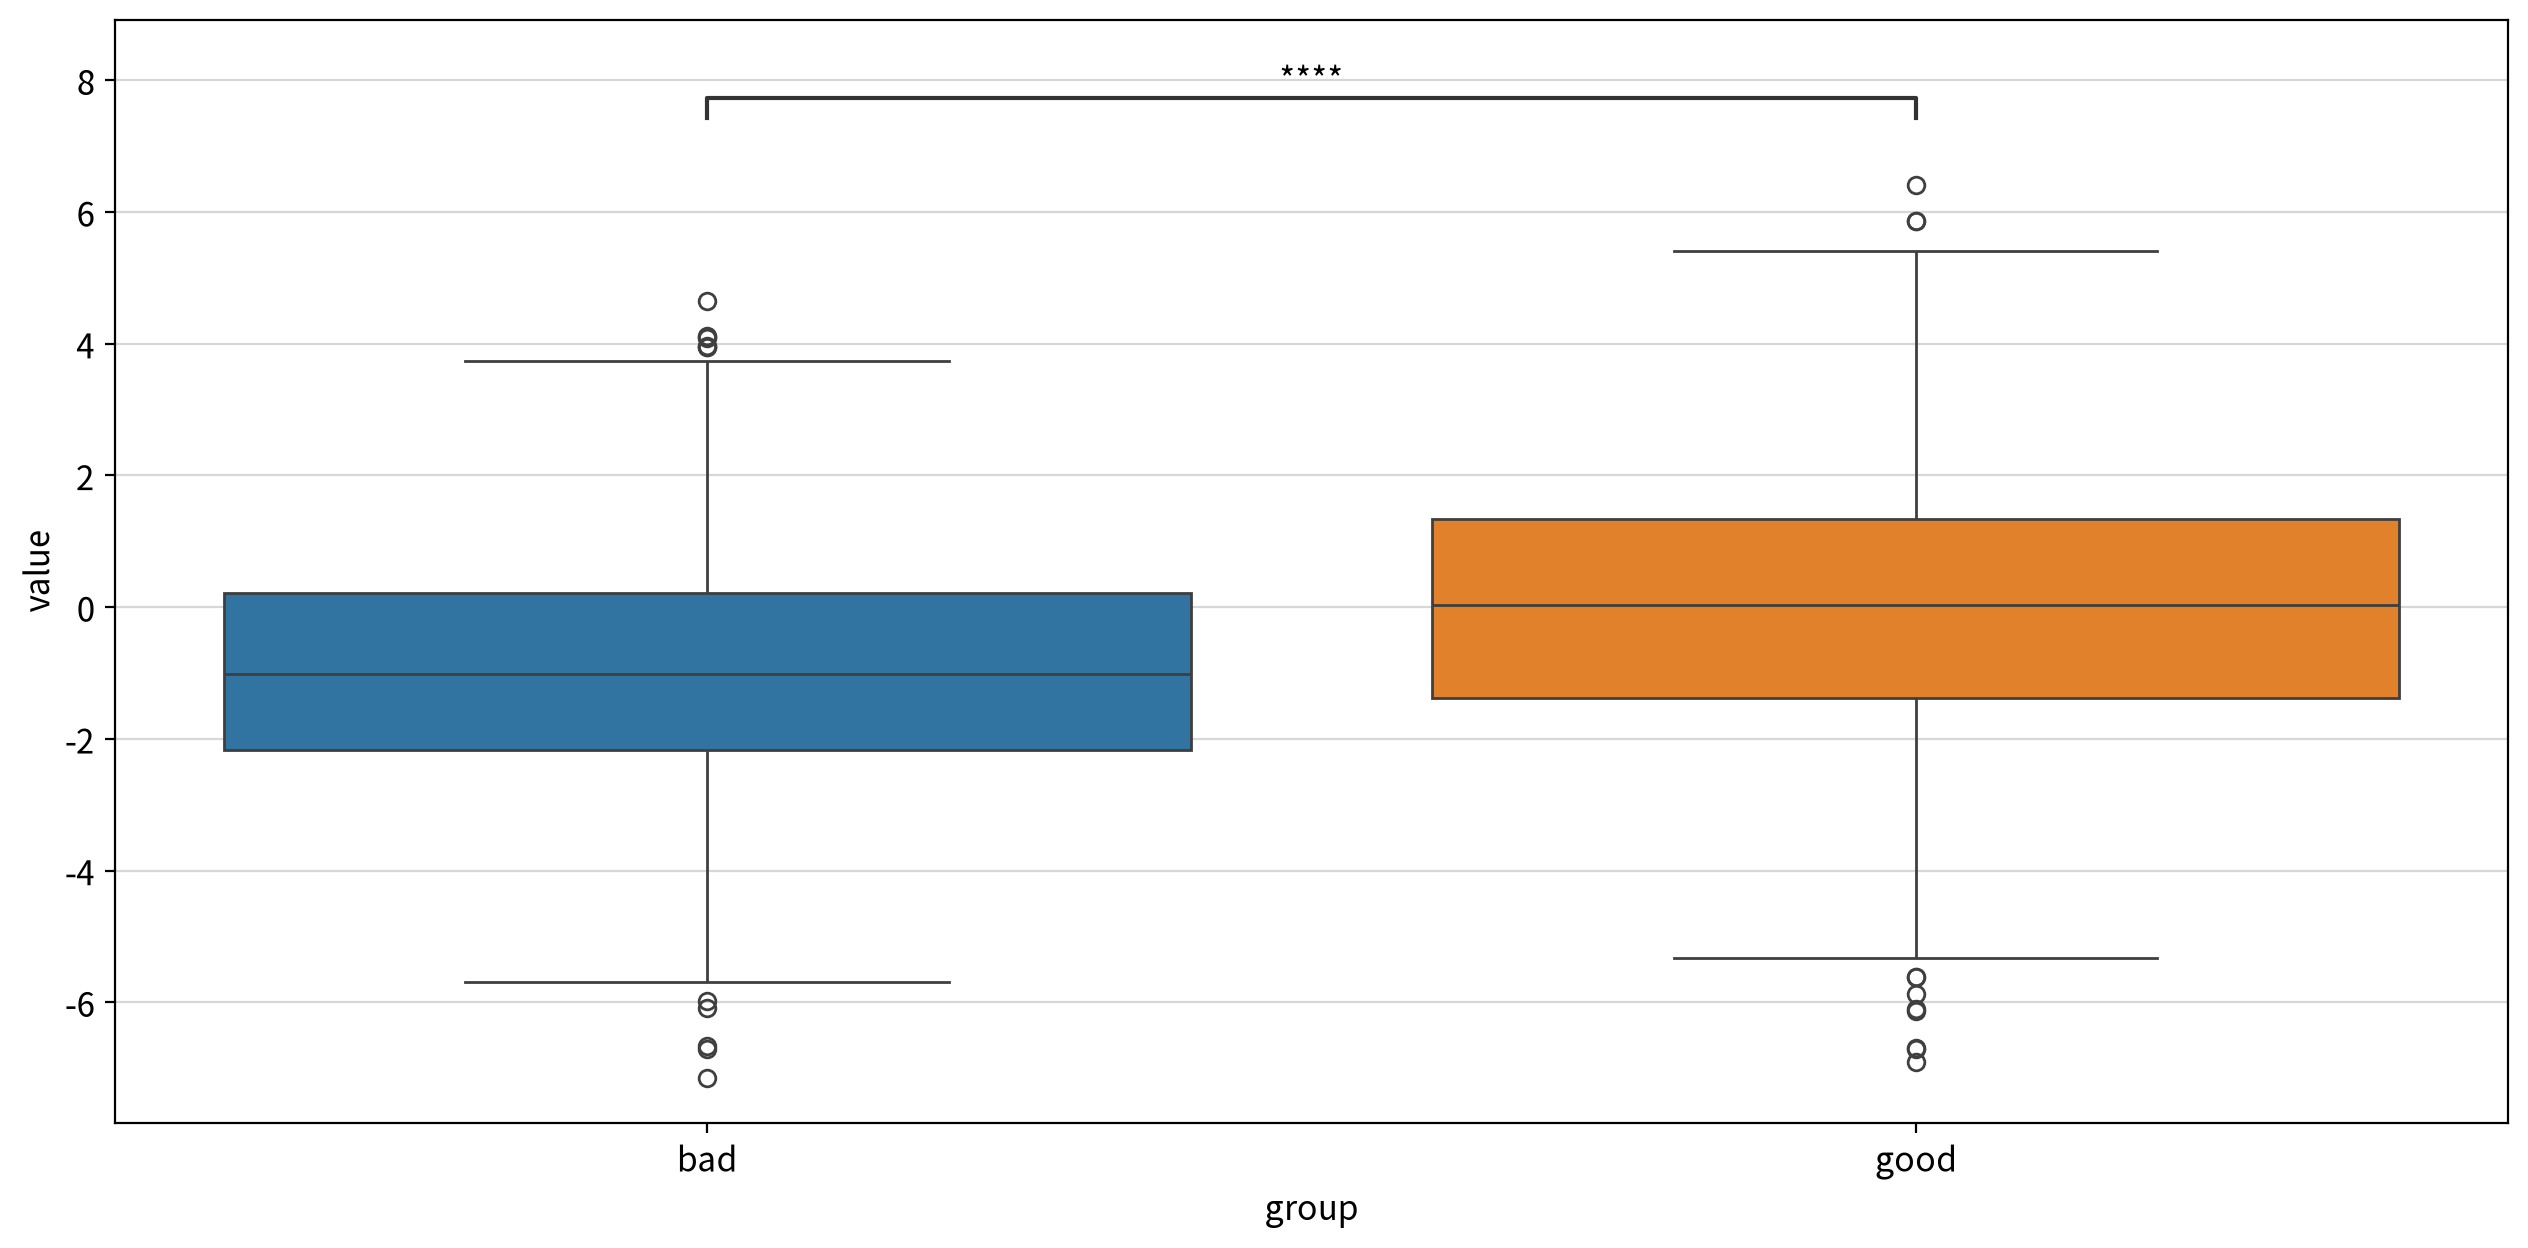

statistic  p-value  significant      result
test                alternative                                              
Mann-Whitney U test two-sided   1433524.000    0.000         True  bad ≠ good
                    less        1433524.000    0.000         True  bad < good
                    greater     1433524.000    1.000        False  bad ≤ good

#### ▶︎ Weight(무게) → Quality

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

bad vs. good: Welch's t-test independent samples, P_val:9.284e-01 t=-8.991e-02


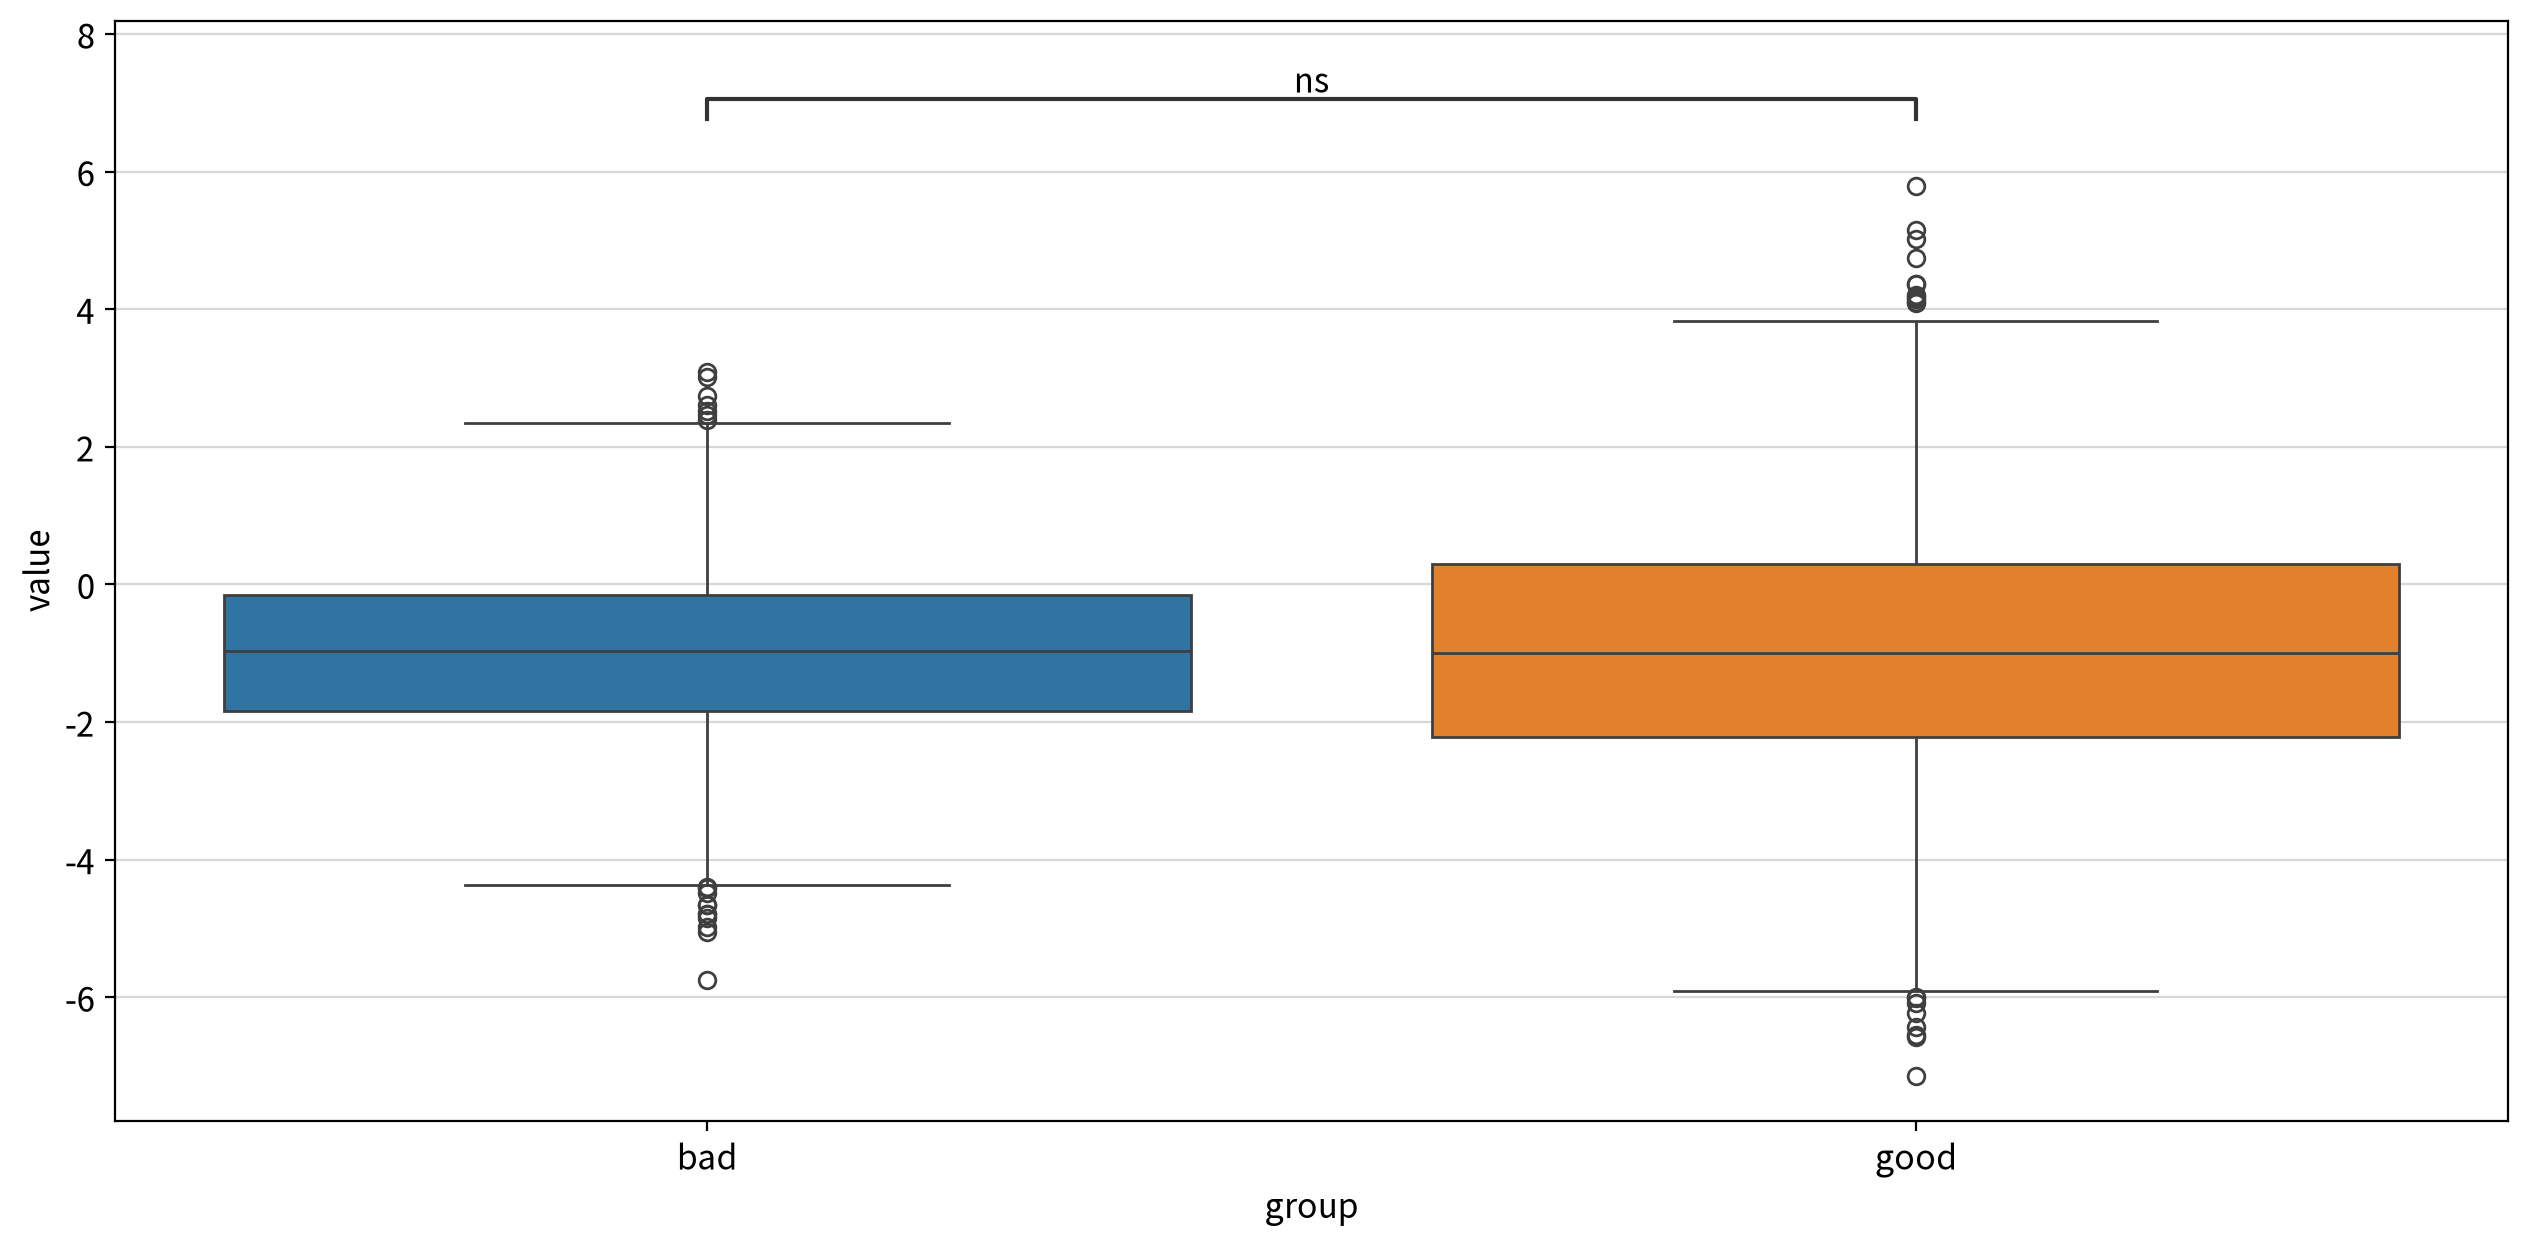

statistic  p-value  significant      result
test         alternative                                             
Welch t-test two-sided       -0.090    0.928        False  bad = good
             less            -0.090    0.464        False  bad ≥ good
             greater         -0.090    0.536        False  bad ≤ good

#### ▶︎ Sweetness(단맛 정도) → Quality

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

bad vs. good: Mann-Whitney-Wilcoxon test two-sided, P_val:0.000e+00 U_stat=1.452e+06


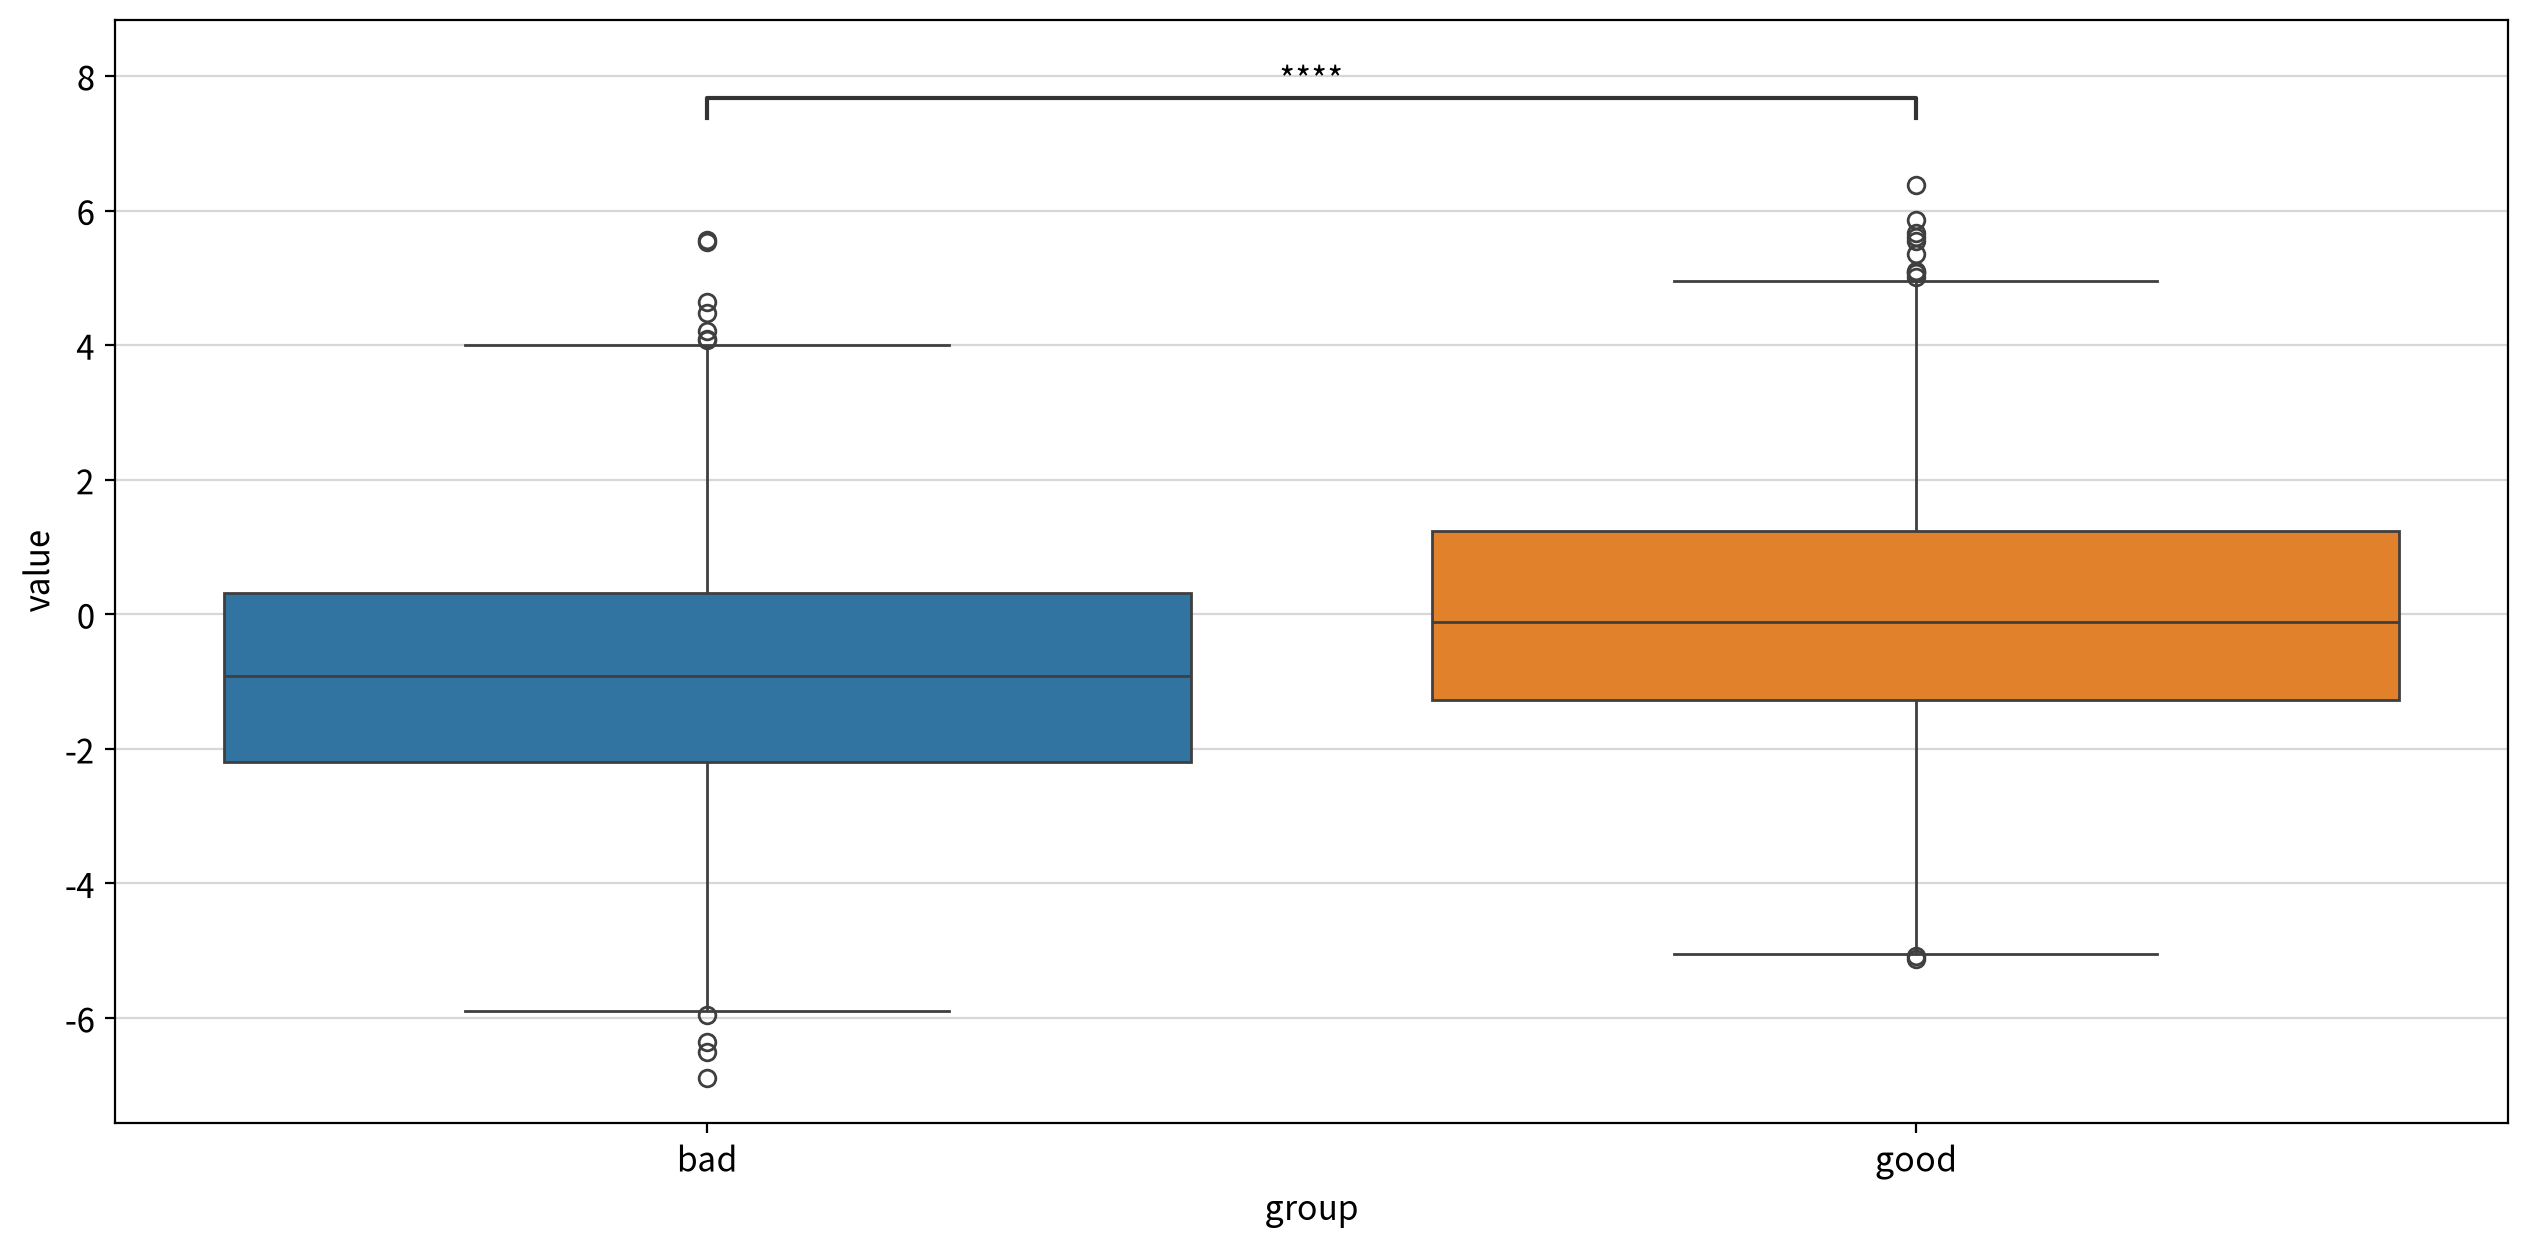

statistic  p-value  significant      result
test                alternative                                              
Mann-Whitney U test two-sided   1452149.000    0.000         True  bad ≠ good
                    less        1452149.000    0.000         True  bad < good
                    greater     1452149.000    1.000        False  bad ≤ good

#### ▶︎ Crunchiness(아삭한 식감) → Quality

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

bad vs. good: Mann-Whitney-Wilcoxon test two-sided, P_val:9.852e-01 U_stat=1.999e+06


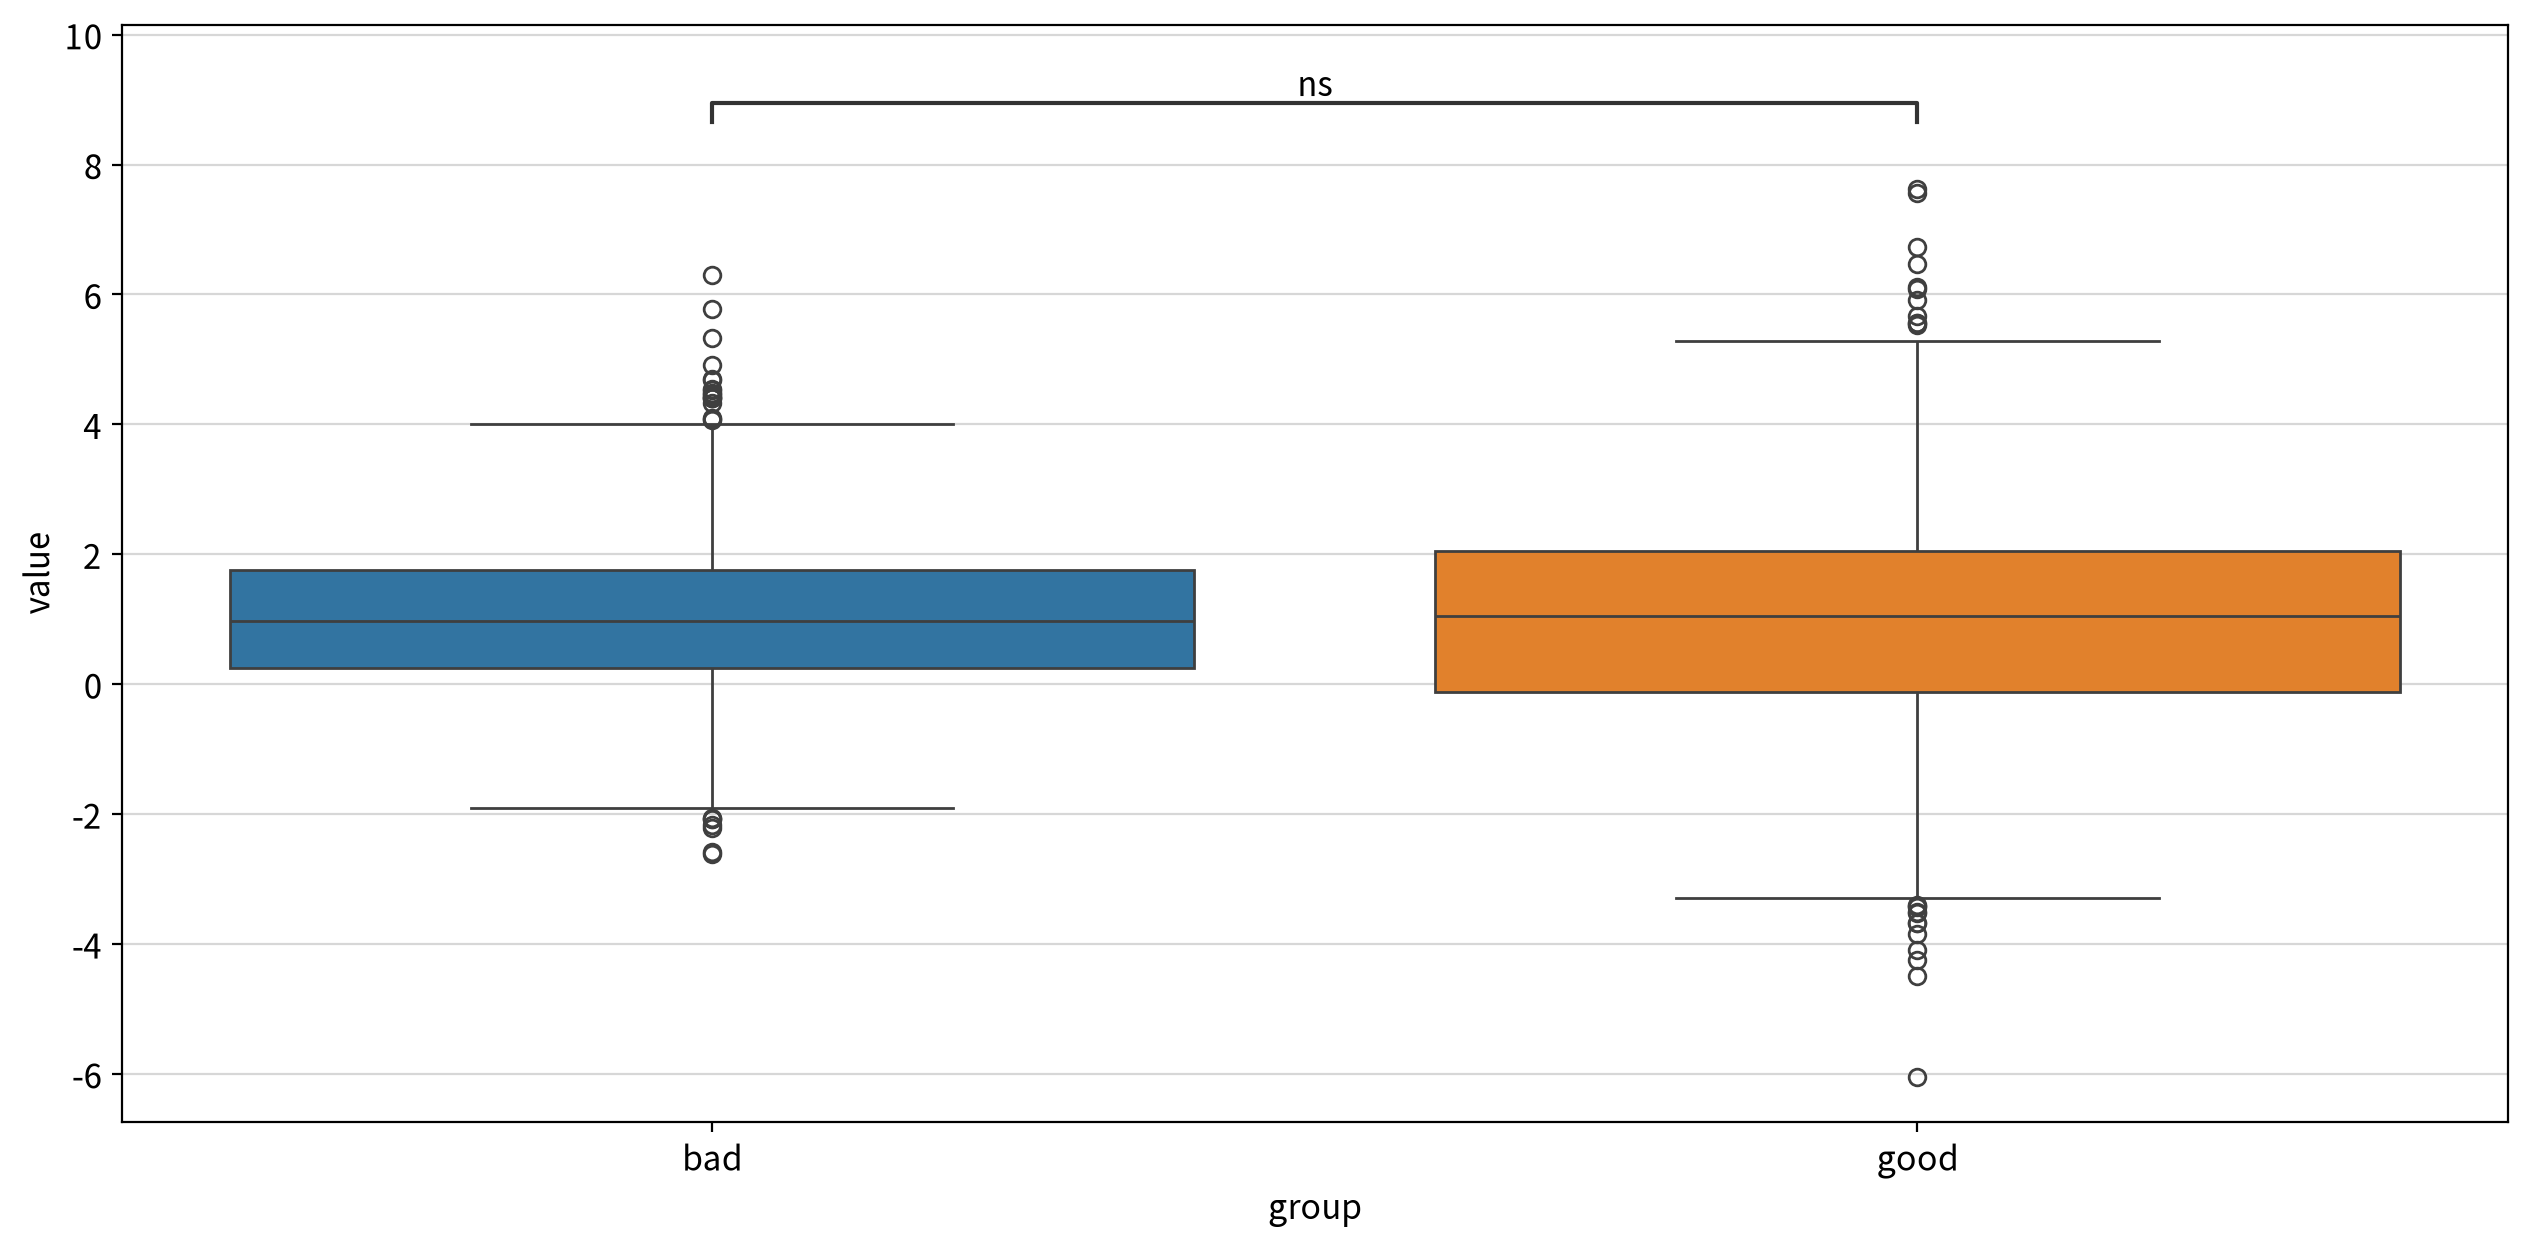

statistic  p-value  significant      result
test                alternative                                              
Mann-Whitney U test two-sided   1999316.000    0.985        False  bad = good
                    less        1999316.000    0.493        False  bad ≥ good
                    greater     1999316.000    0.507        False  bad ≤ good

#### ▶︎ Juiciness(과즙 함량) → Quality

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

bad vs. good: Welch's t-test independent samples, P_val:0.000e+00 t=-1.703e+01


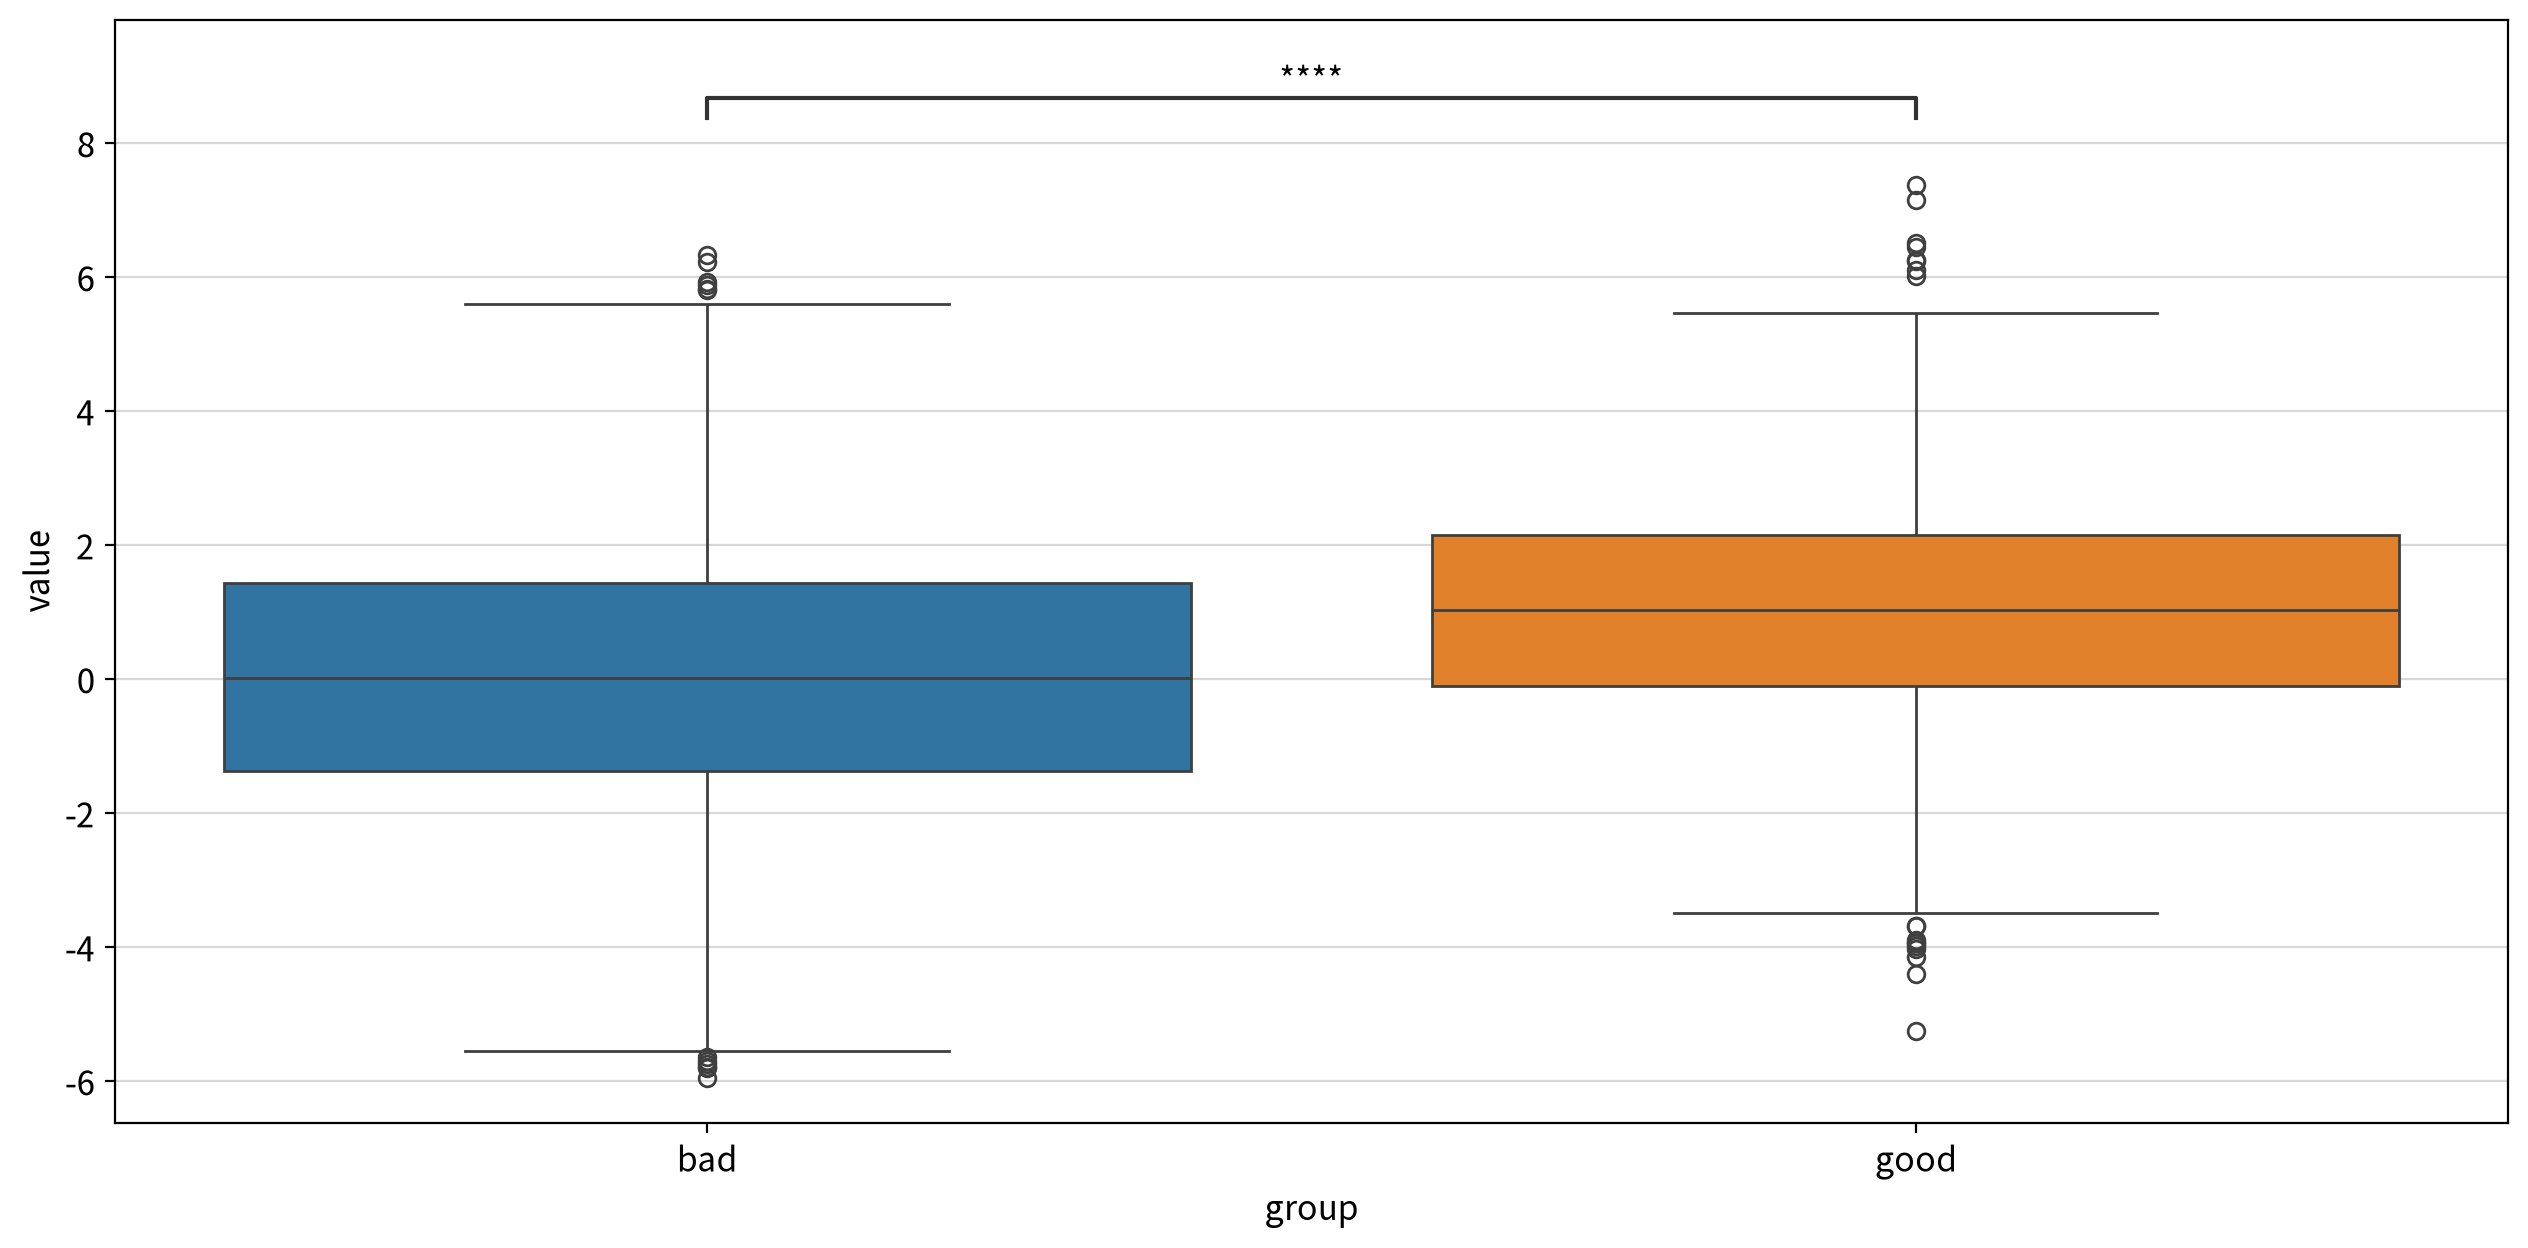

statistic  p-value  significant      result
test         alternative                                             
Welch t-test two-sided      -17.035    0.000         True  bad ≠ good
             less           -17.035    0.000         True  bad < good
             greater        -17.035    1.000        False  bad ≤ good

#### ▶︎ Ripeness(익은 정도) → Quality

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

bad vs. good: Welch's t-test independent samples, P_val:0.000e+00 t=1.733e+01


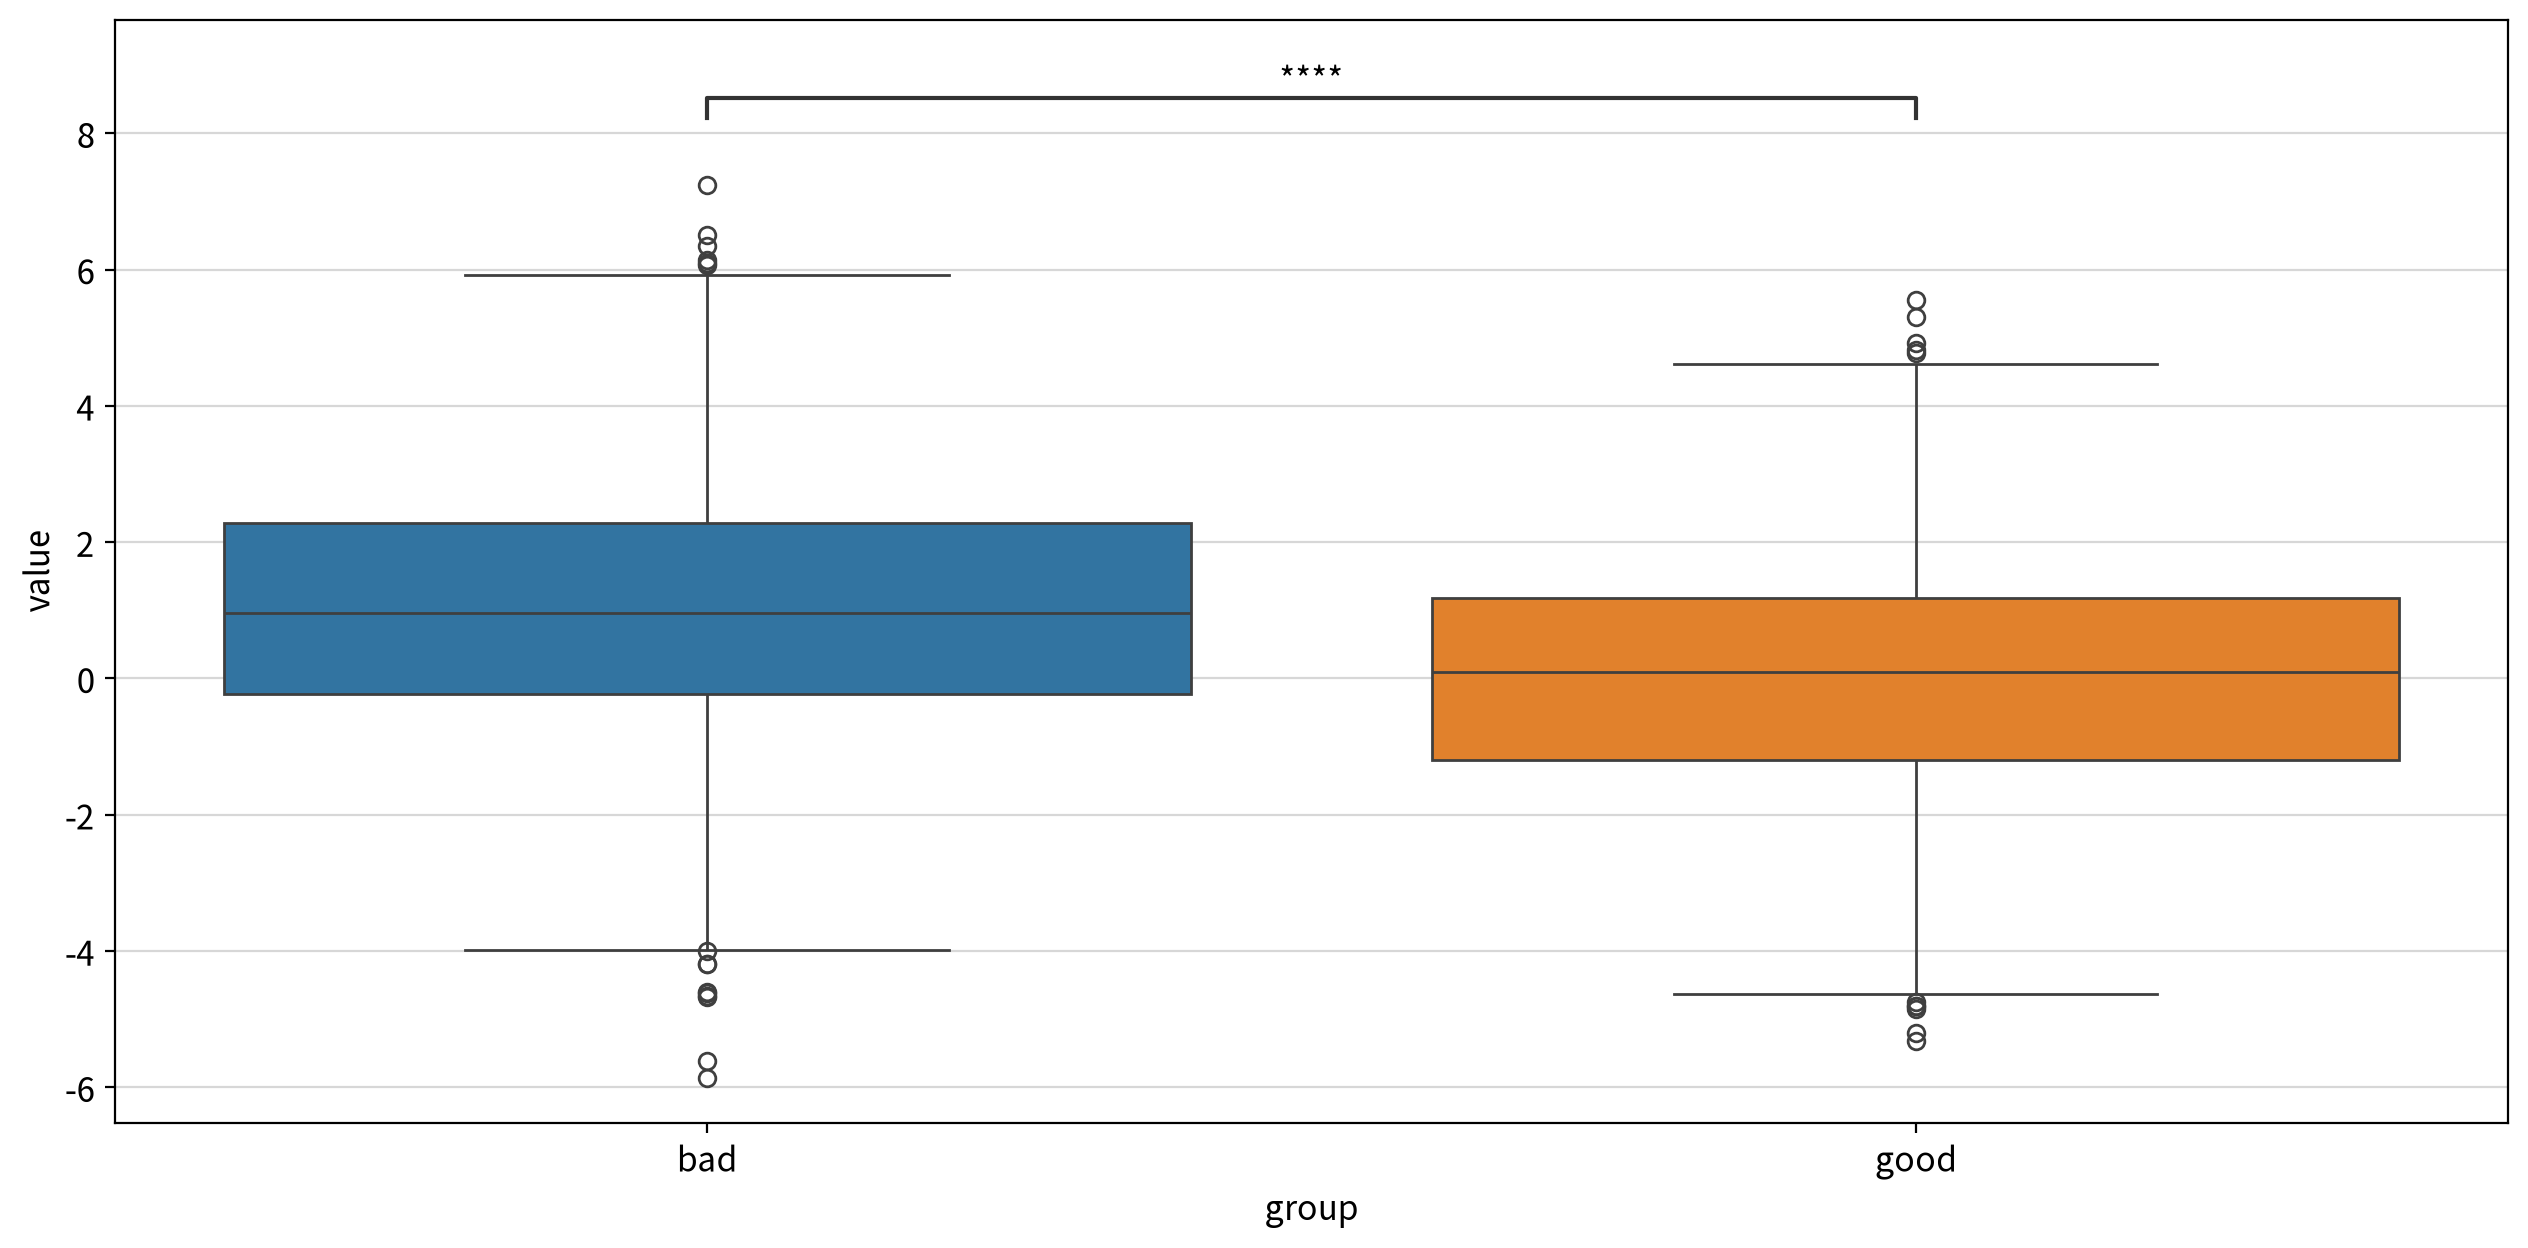

statistic  p-value  significant      result
test         alternative                                             
Welch t-test two-sided       17.326    0.000         True  bad ≠ good
             less            17.326    1.000        False  bad ≥ good
             greater         17.326    0.000         True  bad > good

#### ▶︎ Acidity(산도) → Quality

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

bad vs. good: Mann-Whitney-Wilcoxon test two-sided, P_val:7.970e-01 U_stat=1.991e+06


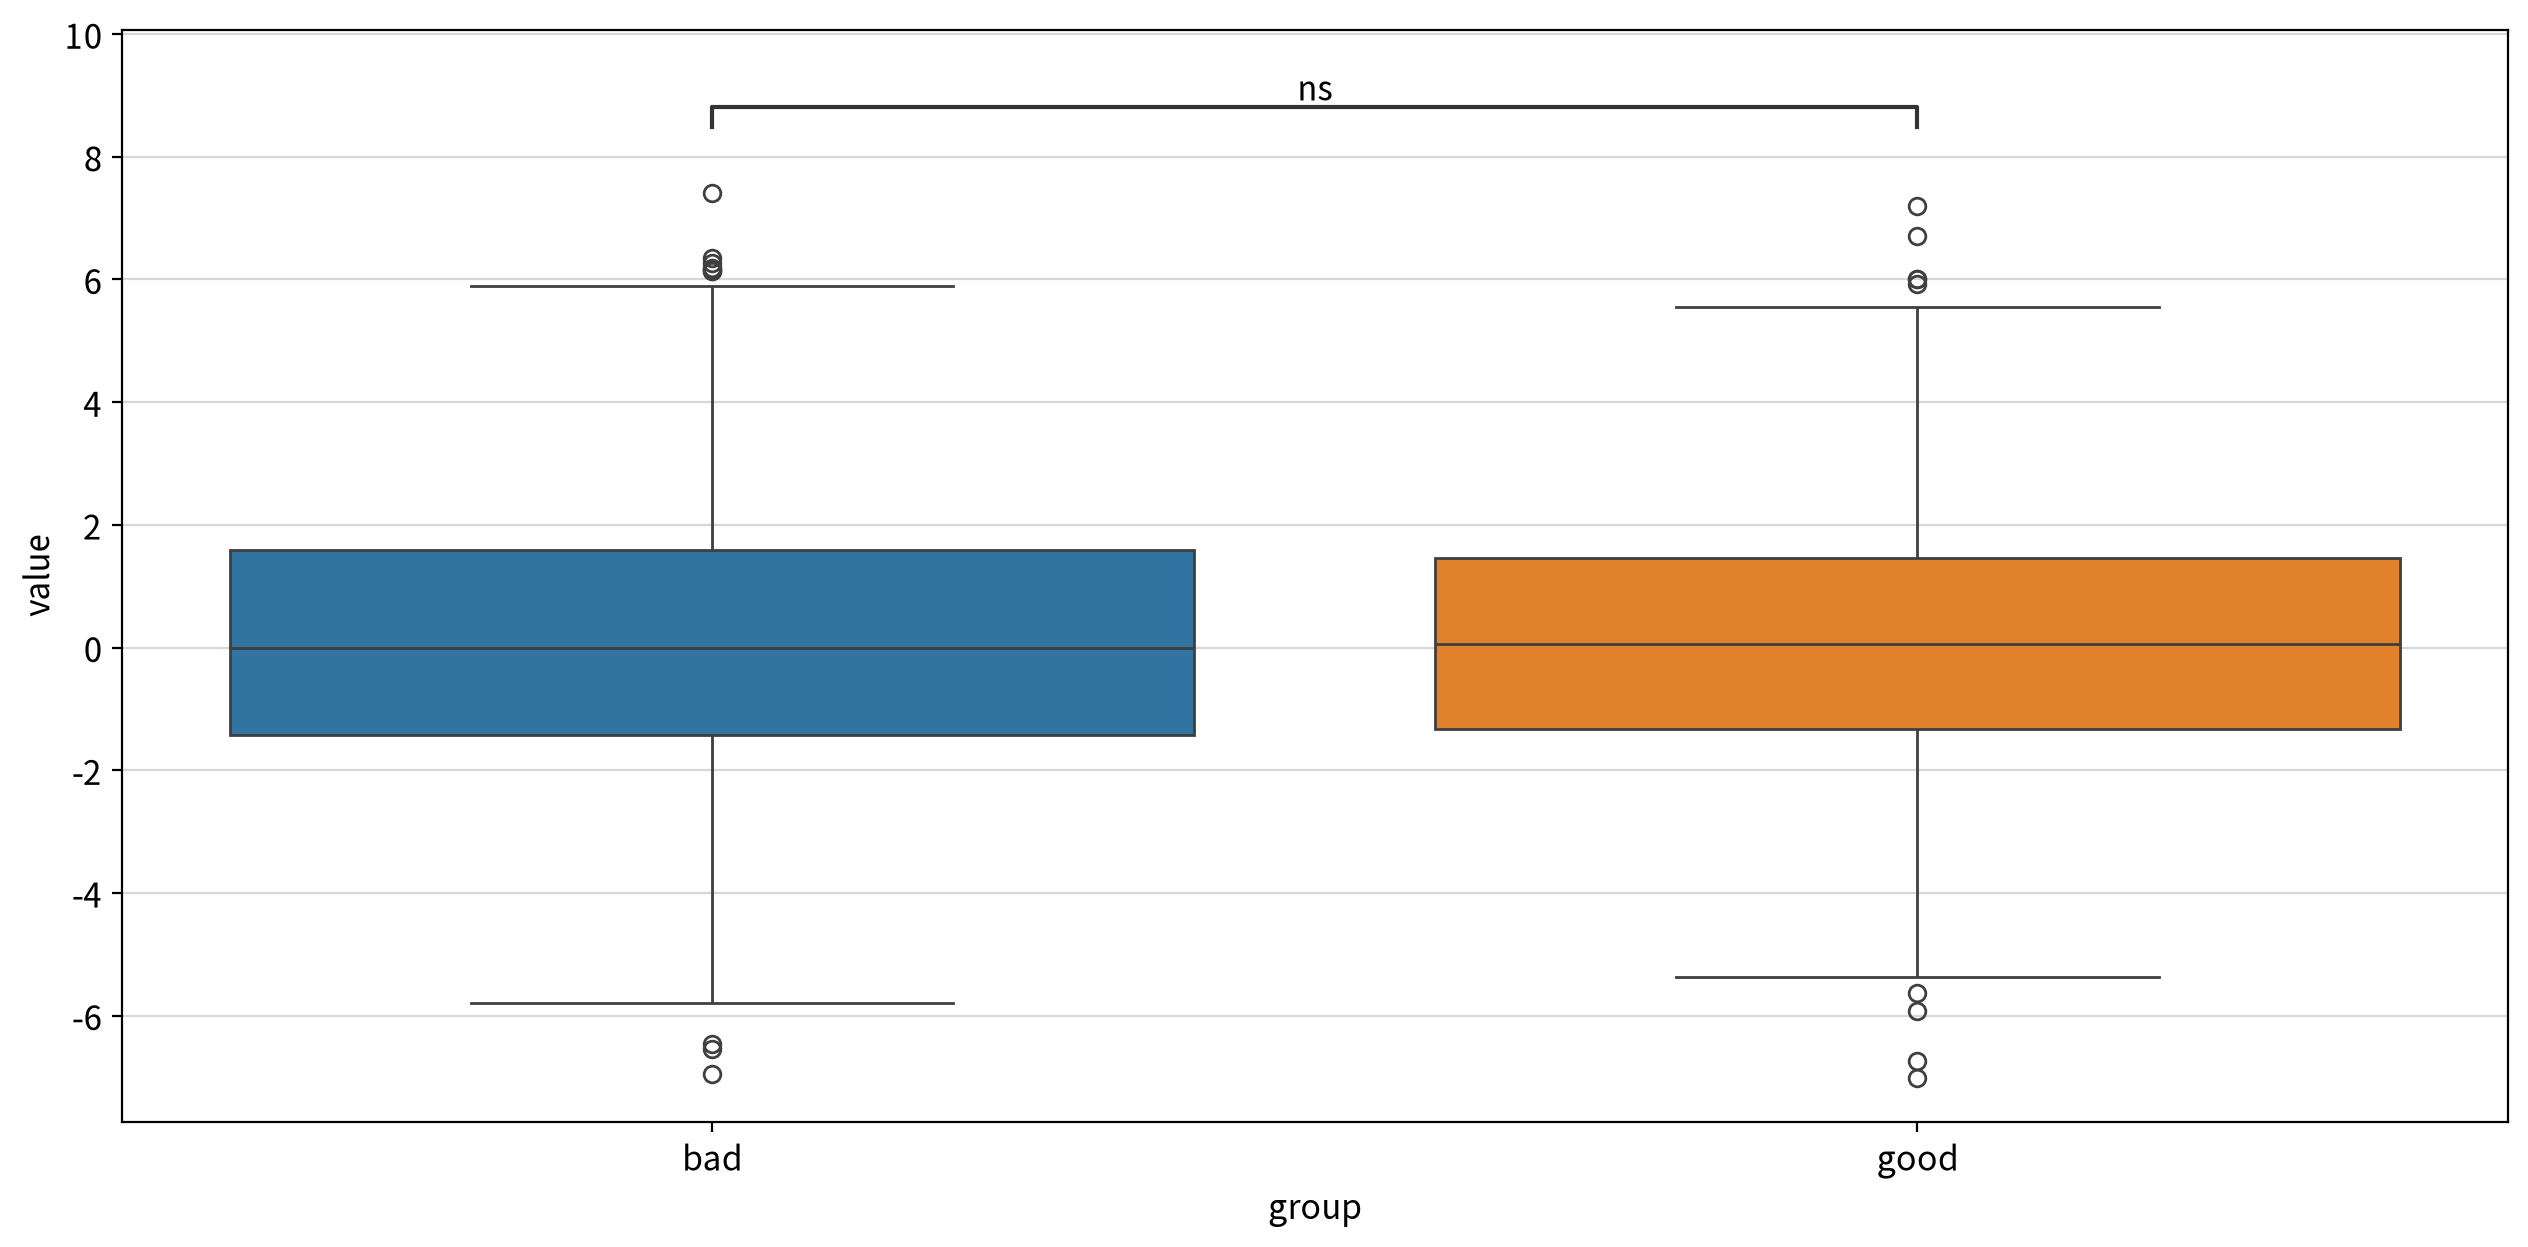

statistic  p-value  significant      result
test                alternative                                              
Mann-Whitney U test two-sided   1990597.000    0.797        False  bad = good
                    less        1990597.000    0.399        False  bad ≥ good
                    greater     1990597.000    0.602        False  bad ≤ good

In [41]:
# 연속형 독립변수 이름을 탐색하면서 반복
for f in continuous_cols:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {f}({column_means[f]}) → {target}"))

    # 수집된 데이터가 long 타입이므로 검정 대상만 wide 타입으로 변환해야 한다.
    # -> 선형회귀 때와 hue/values 가 서로 뒤바뀐다. (종속변수가 집단 기준이 되므로)
    wide_df = my_prep.long2wide(df=df2, hue=target, values=f)
    display(my_stats.test_independent(wide_df,
                                      group1=wide_df.columns[0], group2=wide_df.columns[1]))

>##### 💡 인사이트
>
>| 변수 | 검정 방법 | 유의확률 | 집단 차이 | 방향 | 단독 판정 |
>|---|---|---|---|---|---|
>| `Size` | Mann-Whitney U | < 0.001 | 유의 | `bad` < `good` | ✅ 채택 |
>| `Sweetness` | Mann-Whitney U | < 0.001 | 유의 | `bad` < `good` | ✅ 채택 |
>| `Juiciness` | Welch t | < 0.001 | 유의 | `bad` < `good` | ✅ 채택 |
>| `Ripeness` | Welch t | < 0.001 | 유의 | `bad` > `good` | ✅ 채택 |
>| `Weight` | Welch t | 0.928 | **차이 없음** | — | 🟡 보류 |
>| `Acidity` | Mann-Whitney U | 0.797 | **차이 없음** | — | 🟡 보류 |
>| `Crunchiness` | Mann-Whitney U | 0.985 | **차이 없음** | — | 🟡 보류 |
>
>- 크기 · 단맛 · 과즙은 `good` 사과가 더 높고, 숙성도는 `good` 사과가 더 낮다(덜 익었다).
>- `Weight` · `Acidity` · `Crunchiness`는 **두 집단의 평균이 같았다.** 다만 '평균이 같다'는 것은 '관계가 없다'와 다를 수 있으므로 버리지 않고 모델에서 다시 확인한다.
>- 결과표의 `bad = good` 같은 표기는 '같다고 증명됐다'가 아니라 **'차이가 있다고 말할 근거가 없다'** 는 뜻이다.

## 2-3. 다변량 분석

### (1) 독립변수간 상관 분석

- 연속형 독립변수끼리는 종속변수가 명목형이어도 상관분석을 그대로 쓸 수 있다.
- 목적이 다르다. 여기서는 **설명력 확인이 아니라 다중공선성 점검**이다.

In [42]:
corr = my_stats.multi_correlation(data=df2, columns=continuous_cols, plot=False)
my_stats.correlation_summary(corr)

,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity
Size,1.000,-0.144,-0.325,0.172,-0.032,-0.155,0.210
Weight,-0.144,1.000,-0.120,-0.087,-0.091,-0.244,0.030
Sweetness,-0.325,-0.120,1.000,-0.017,0.098,-0.255,0.072
Crunchiness,0.172,-0.087,-0.017,1.000,-0.236,-0.184,0.074
Juiciness,-0.032,-0.091,0.098,-0.236,1.000,-0.124,0.231
Ripeness,-0.155,-0.244,-0.255,-0.184,-0.124,1.000,-0.195
Acidity,0.210,0.030,0.072,0.074,0.231,-0.195,1.000


,max-y,max-coef,count,columns
x,,,,
Size,Sweetness,-0.325,0,-
Sweetness,Size,-0.325,0,-
Ripeness,Sweetness,-0.255,0,-
Weight,Ripeness,-0.244,0,-
Crunchiness,Juiciness,-0.236,0,-
Juiciness,Crunchiness,-0.236,0,-
Acidity,Juiciness,0.231,0,-


>##### 💡 인사이트
>
>- `correlation_summary()`에서 **강한 상관(|r| ≥ 0.7) 조합이 하나도 나오지 않았다.** 가장 강한 쌍도 `Size` ↔ `Sweetness`(−0.325)다.
>- → **다중공선성 문제 없음.** 7개 변수를 모두 투입해도 계수가 불안정해지지 않는다.

## 2-4. 최종 변수 선택

| 채택여부 | 변수 | 검정방법 | 유의확률 | 방향 | 공선성 신호 (VIF) | 근거 |
|---|---|---|---|---|---|---|
| ✅ 채택 | `Size` | Mann-Whitney U | < 0.001 | `bad` < `good` | X (VIF 1.41) | 집단 차이 유의 |
| ✅ 채택 | `Sweetness` | Mann-Whitney U | < 0.001 | `bad` < `good` | X (VIF 1.48) | 집단 차이 유의 |
| ✅ 채택 | `Juiciness` | Welch t | < 0.001 | `bad` < `good` | X (VIF 1.22) | 집단 차이 유의 |
| ✅ 채택 | `Ripeness` | Welch t | < 0.001 | `bad` > `good` | X (VIF 1.48) | 집단 차이 유의 (유일한 음의 방향) |
| 🟡 보류 | `Weight` | Welch t | 0.928 | — | X (VIF 1.35) | 단독 차이는 없으나 **억제효과 가능성** → 투입 후 계수로 판정 |
| 🟡 보류 | `Acidity` | Mann-Whitney U | 0.797 | — | X (VIF 1.17) | 단독 차이는 없으나 **억제효과 가능성** → 투입 후 계수로 판정 |
| 🟡 보류 | `Crunchiness` | Mann-Whitney U | 0.985 | — | X (VIF 1.22) | 단독 차이는 없으나 **억제효과 가능성** → 투입 후 계수로 판정 |
| ❌ 제외 | `A_id` | — | — | — | — | 행마다 값이 다른 **식별자** (PART 1에서 제거) |

- **제외는 `A_id` 하나뿐**이다. 나머지 7종은 전부 모델에 투입한 뒤 **후진소거법으로 판정**한다.
- 이유: 공선성이 없어 변수를 다 넣어도 부작용이 없고, T검정에서 탈락한 3종은 **다른 변수를 통제했을 때 살아날 수 있기 때문**이다.

- 공선성 칸의 VIF는 PART 3 기준선 모형의 계수표에서 확인한 값이다.

---
# PART 3. 기준선 모형과 가정 검정

## 3-1. 기준선 모형

### (1) 로지스틱 회귀 기준선 모형

- 종속변수 라벨링

    - 로지스틱 회귀의 종속변수는 **0/1의 정수**여야 한다. 문자열 `good`/`bad`를 숫자로 바꾼다.
    - `my_prep.labeling()`은 **알파벳 순서**로 0부터 매긴다. → `bad = 0`, `good = 1`
    - 즉 이 모형이 예측하는 것은 **P(Quality = good)** 이고,
    뒤에 나오는 오즈비는 모두 **"사과가 `good`일 오즈"** 에 대한 값이다.

In [43]:
df2 = my_prep.labeling(df=df2, columns=[target])
df2.head()

Quality (2종): bad=0, good=1


,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity,Quality
0,-3.970,-2.512,5.346,-1.012,1.845,0.330,-0.492,1
1,-1.195,-2.839,3.664,1.588,0.853,0.868,-0.723,1
2,-0.292,-1.351,-1.738,-0.343,2.839,-0.038,2.622,0
3,-0.657,-2.272,1.325,-0.098,3.638,-3.414,0.791,1
4,1.364,-1.297,-0.385,-0.553,3.031,-1.304,0.502,1


### (2) 기준선 모형 적합

In [44]:
fit = my_logit.fit_model(data=df2, y=target)
my_logit.report_variables(fit=fit, data=df2)

,종속변수,독립변수,B,β,표준오차,z,유의확률,B 95% 하한,B 95% 상한,오즈비(OR),OR 95% 하한,OR 95% 상한,공차,VIF
0,Quality,Size,0.649,1.252,0.028,22.993,0.000,0.594,0.705,1.915,1.811,2.024,0.708,1.413
1,Quality,Sweetness,0.569,1.105,0.027,20.938,0.000,0.516,0.622,1.766,1.675,1.863,0.677,1.477
2,Quality,Juiciness,0.442,0.854,0.024,18.242,0.000,0.395,0.490,1.556,1.484,1.632,0.820,1.219
3,Quality,Acidity,-0.294,-0.621,0.021,-13.697,0.000,-0.336,-0.252,0.745,0.714,0.777,0.853,1.172
4,Quality,Weight,0.267,0.427,0.028,9.399,0.000,0.211,0.322,1.306,1.235,1.380,0.742,1.348
5,Quality,Ripeness,-0.127,-0.238,0.025,-5.132,0.000,-0.175,-0.078,0.881,0.839,0.925,0.677,1.478
6,Quality,Crunchiness,0.035,0.049,0.030,1.143,0.253,-0.025,0.094,1.035,0.976,1.098,0.821,1.218


>##### 💡 인사이트 — EDA에서 보류했던 변수가 되살아났다
>
>| 변수 | T검정 (단독 비교) | 기준선 모형 (다른 변수 통제) | 판정 |
>|---|---|---|---|
>| `Size` | p < 0.001 | z = 22.99, p < 0.001 | 그대로 유의 |
>| `Sweetness` | p < 0.001 | z = 20.94, p < 0.001 | 그대로 유의 |
>| `Juiciness` | p < 0.001 | z = 18.24, p < 0.001 | 그대로 유의 |
>| `Ripeness` | p < 0.001 | z = −5.13, p < 0.001 | 그대로 유의 |
>| **`Acidity`** | **p = 0.797 (무관)** | **z = −13.70, p < 0.001** | **되살아남** |
>| **`Weight`** | **p = 0.928 (무관)** | **z = 9.40, p < 0.001** | **되살아남** |
>| `Crunchiness` | p = 0.985 (무관) | p = 0.253 | 유일한 탈락 후보 |
>
>- **T검정에서 "차이가 전혀 없다"고 나왔던 `Acidity`와 `Weight`가 p < 0.001로 강하게 유의**해졌다.
>   - 이것이 **억제효과(suppression)** 다. 다른 변수를 통제하지 않은 단독 비교에서는 효과가 가려져 있었던 것이다.
>   - `Acidity`의 오즈비는 **0.745** 로, 산도가 1점 높아지면 `good`일 오즈가 **약 25.5% 감소**한다.
>   - 따라서 **EDA에서 유의하지 않다는 이유만으로 변수를 버리면 안 된다.**
>- 유의하지 않은 변수는 `Crunchiness` 하나뿐이지만, **여기서도 아직 지우지 않는다.**

## 3-2. 가정 검정 — 로짓 선형성

### (1) 기준선 모형의 로짓 선형성 검정 (Box-Tidwell)

- 독립변수 x에 `x × ln(x)` 항을 추가해 **그 항이 유의한지** 본다.
  - 유의하면(p < 0.05) 로짓이 직선이 아니라는 뜻 → 변환·제곱항·구간화가 필요하다.

In [45]:
my_logit.test_linear(fit=fit, data=df2)

,z,p-value,linearity,위치이동,result
독립변수,,,,,
Size,4.323,0.000,False,True,대립가설 채택 → 로짓 선형성 위배 (변환 필요)
Weight,11.161,0.000,False,True,대립가설 채택 → 로짓 선형성 위배 (변환 필요)
Sweetness,0.605,0.545,True,True,귀무가설 채택 → 로짓 선형성 위배 근거 없음
Crunchiness,9.851,0.000,False,True,대립가설 채택 → 로짓 선형성 위배 (변환 필요)
Juiciness,-8.075,0.000,False,True,대립가설 채택 → 로짓 선형성 위배 (변환 필요)
Ripeness,-1.047,0.295,True,True,귀무가설 채택 → 로짓 선형성 위배 근거 없음
Acidity,-5.553,0.000,False,True,대립가설 채택 → 로짓 선형성 위배 (변환 필요)


> ##### [💡 인사이트]
>
>- `Sweetness`(p = 0.545)와 `Ripeness`(p = 0.295)만 충족한다.
>- 7종 중 **5종이 위배**다. (`Weight` z = 11.16, `Crunchiness` z = 9.85, `Juiciness` z = −8.08, `Acidity` z = −5.55, `Size` z = 4.32)
>   - **위배 신호가 가장 강한(|z| = 11.16) `Weight`부터 처방한다.** p-value는 위배된 5개 변수 모두 0.000이라 순위를 매길 수 없어, z의 절댓값으로 우선순위를 정했다.
>
> ※ 이 변수들은 음수를 포함하므로 `ln`의 정의역을 맞추기 위해 **최솟값이 1이 되도록 평행이동**한 뒤 검정된다. (`위치이동 = True`)

### (2) 선형성 위배 처리 — 진단 → 처방 → 검증 → 재진단 루프

- **진단** : 로짓 선형성 검정으로 위배 변수를 찾고, 위배 신호(|z|)가 가장 강한 변수 **하나**를 고른다.
- **처방** : 그 변수에 제곱항을 추가한다. (음수를 포함한 변수라 로그 변환은 후보에서 빠진다)
- **검증** : 제곱항이 유의하고, 우도비 검정으로 모형이 실제로 좋아졌는지 확인한다.
- **재진단** : 한 변수를 고치면 다른 변수의 진단도 바뀌므로, **처음부터 다시 진단**한다. 위배 변수가 없어질 때까지 반복한다.

In [46]:
fit_fixed = my_logit.fix_linear(data=df2, y=target)

[라운드 1] 위배 5종 → 'Weight' 처방 (z = 11.1613)
     → 제곱항 채택 (제곱항 p = 0.0000, 우도비 p = 0.0000e+00, AIC = 3962.44)
[라운드 2] 위배 5종 → 'Crunchiness' 처방 (z = 9.0855)
     → 제곱항 채택 (제곱항 p = 0.0000, 우도비 p = 0.0000e+00, AIC = 3867.27)
[라운드 3] 위배 3종 → 'Juiciness' 처방 (z = -10.5276)
     → 제곱항 채택 (제곱항 p = 0.0000, 우도비 p = 0.0000e+00, AIC = 3744.33)
[라운드 4] 위배 3종 → 'Acidity' 처방 (z = -7.4836)
     → 제곱항 채택 (제곱항 p = 0.0000, 우도비 p = 3.2307e-14, AIC = 3688.74)
[라운드 5] 위배 2종 → 'Ripeness' 처방 (z = -3.0869)
     → 제곱항 채택 (제곱항 p = 0.0023, 우도비 p = 2.1255e-03, AIC = 3681.30)
[라운드 6] 위배 1종 → 'Size' 처방 (z = 2.9542)
     → 제곱항 채택 (제곱항 p = 0.0025, 우도비 p = 2.2468e-03, AIC = 3673.97)
[라운드 7] 위배 변수 없음 → 루프 종료



,변수,처방,제곱항 p,검증 p,AIC,채택
라운드,,,,,,
1,Weight,제곱항,0.000,0.000,3962.440,True
2,Crunchiness,제곱항,0.000,0.000,3867.270,True
3,Juiciness,제곱항,0.000,0.000,3744.330,True
4,Acidity,제곱항,0.000,0.000,3688.740,True
5,Ripeness,제곱항,0.002,0.002,3681.300,True
6,Size,제곱항,0.003,0.002,3673.970,True


>##### 💡 인사이트 — 하나씩 처방하니 `Crunchiness`도 해소됐다
>
>- 6개 라운드에 걸쳐 **`Weight` → `Crunchiness` → `Juiciness` → `Acidity` → `Ripeness` → `Size`** 순으로 위배가 심한 변수부터 하나씩 처방됐고, **7라운드에서 위배 변수가 사라져 루프가 종료**됐다.
>   - `Sweetness`는 끝까지 위배로 잡히지 않아 **원본 그대로 남았다.**
>- 라운드마다 위배 변수의 개수가 5 → 5 → 3 → 3 → 2 → 1 → 0으로 줄어드는데, **한 번에 하나씩 줄지 않는다.**
>   - 한 변수를 고치면 다른 변수의 진단이 함께 바뀌기 때문이다. 이것이 재진단을 반드시 해야 하는 이유다.
>- 처방 순서도 눈여겨볼 만하다. `Crunchiness`는 **T검정에서 p = 0.985로 완전 무관**이었고 **기준선 모형에서도 p = 0.253으로 제거 후보**였는데, 로짓 선형성 진단에서는 **두 번째로 심한 위배**로 잡힌다.
>   - Crunchiness와 품질의 관계가 U자로 양 극단이 모두 `good` 쪽이라 평균 비교로는 상쇄되어 보이지 않았을 뿐이다.

### (3) 계층 원칙(hierarchy principle)

- 제곱항을 넣으면 1차항이 유의하지 않게 나오는 경우가 있다. 후진소거법이라면 제거 대상이다.
- 하지만 **제곱항이 모형에 있으면 1차항은 유의하지 않아도 남긴다.** 이것을 **계층 원칙(hierarchy principle)** 이라 한다.
  - 1차항을 빼면 곡선의 **꼭짓점이 중심값(0)에 고정**되어 버려, 데이터가 말하는 곡선 모양을 왜곡한다.
- 실제로 지워도 되는지는 **PART 4의 성능 비교표**에서 후진소거 적용 모형과 나란히 놓고 판단한다.

### (4) 독립성 검정 — Durbin-Watson

In [47]:
my_logit.test_independent(fit_fixed)

,statistic,independence,result
Durbin-Watson,2.022,True,독립성 만족


> ##### [💡 인사이트]
>
>- DW = **2.02**로 기준 범위(1.5 ~ 2.5)의 한가운데다. → **독립성 만족.**
>- 관측치 사과 4,000개는 서로 다른 개체이고 수집 순서에 의미가 없으므로 설계상으로도 독립이 타당하다.

### (5) 가정 검정 결과 확정

- 처방 대상 변수 목록을 확정한다. 이 목록이 **다음 단계 파이프라인의 옵션**이 된다.

In [48]:
# 변수별 확정된 처방 내역 딕셔너리 (처방 방식과 기준값)
recipe = fit_fixed.recipe_

for col, rule in recipe.items():            # 키, 값
    print(f"{col:14s} : {rule['method']}")

extra_cols = [c for c in continuous_cols if c not in recipe]
print("\n처방 제외 (선형성 충족) :", extra_cols)
print("미해소 (구간화·스플라인 필요) :", fit_fixed.unresolved_)

Weight         : square
Crunchiness    : square
Juiciness      : square
Acidity        : square
Ripeness       : square
Size           : square

처방 제외 (선형성 충족) : ['Sweetness']
미해소 (구간화·스플라인 필요) : []


---
# PART 4. 로지스틱 회귀 모델링

- `my_logit.fit_pipeline()`은 처방(`recipe`) 적용 → 공선성 제거 → 이상치 대체 → 정규화 → 후진소거를 옵션에 따라 한 번에 수행한다.
- 전처리 조합을 체크포인트로 정의해 같은 데이터에 적용하고, 성능을 한 표에서 비교한다.

### (1) 전처리 체크포인트 정의

- 전처리 단계를 하나씩 누적한 체크포인트 (아래로 갈수록 전처리가 하나 더 붙는다)
- **0~3번은 가정 검정을 반영하지 않은 조합**, **4~7번은 `recipe`를 적용한 조합**이다.
  - 두 계열의 전처리 조합을 **동일하게 맞춰** 로짓 선형성 처방의 순수한 효과를 볼 수 있게 한다.
- 공선성 제거(`vif=True`)는 **모든 체크포인트에 공통으로** 걸어 둔다.
  - PART 2 다변량 분석에서 이미 공선성 문제가 없음을 확인했으므로, 별도의 비교 단계로 쪼갤 이유가 없다.

In [49]:
checkpoints = {
    # --- 가정 검정 미반영 ---
    "0_기준선":             dict(vif=True),
    "1_후진소거":           dict(backward=True, vif=True),
    "2_이상치대체":         dict(backward=True, outlier=True, vif=True),
    "3_정규화":             dict(backward=True, outlier=True, vif=True, scale=True),

    # --- 가정 검정 반영 (로짓 선형성 처방) ---
    "4_가정반영":           dict(recipe=recipe, vif=True),
    "5_가정반영+후진소거":   dict(recipe=recipe, backward=True, vif=True),
    "6_가정반영+이상치대체": dict(recipe=recipe, backward=True, outlier=True, vif=True),
    "7_가정반영+정규화":     dict(recipe=recipe, backward=True, outlier=True, vif=True, scale=True),
}

### (2) 체크포인트별 모델 적합

In [50]:
fits = {}    # 적합된 모델을 누적할 딕셔너리

for name in checkpoints:
    print(f"\n▶︎ --- {name} ---")

    fits[name] = my_logit.fit_pipeline(data=df2, y=target, columns=continuous_cols, 
                                       name=name, **checkpoints[name])

print("\n누적된 모델 :", len(fits), "개")


▶︎ --- 0_기준선 ---

완료! 남은 변수: ['Acidity', 'Crunchiness', 'Juiciness', 'Ripeness', 'Size', 'Sweetness', 'Weight']
최대 VIF = 1.48


▶︎ --- 1_후진소거 ---

완료! 남은 변수: ['Acidity', 'Crunchiness', 'Juiciness', 'Ripeness', 'Size', 'Sweetness', 'Weight']
최대 VIF = 1.48

유의하지 않은 독립변수 제거 → Crunchiness (p = 0.2532)

▶︎ --- 2_이상치대체 ---

완료! 남은 변수: ['Acidity', 'Crunchiness', 'Juiciness', 'Ripeness', 'Size', 'Sweetness', 'Weight']
최대 VIF = 1.47

유의하지 않은 독립변수 제거 → Crunchiness (p = 0.3016)

▶︎ --- 3_정규화 ---

완료! 남은 변수: ['Acidity', 'Crunchiness', 'Juiciness', 'Ripeness', 'Size', 'Sweetness', 'Weight']
최대 VIF = 1.47

유의하지 않은 독립변수 제거 → Crunchiness (p = 0.3016)

▶︎ --- 4_가정반영 ---

완료! 남은 변수: ['Acidity_c', 'Acidity_c2', 'Crunchiness_c', 'Crunchiness_c2', 'Juiciness_c', 'Juiciness_c2', 'Ripeness_c', 'Ripeness_c2', 'Size_c', 'Size_c2', 'Sweetness', 'Weight_c', 'Weight_c2']
최대 VIF = 1.61


▶︎ --- 5_가정반영+후진소거 ---

완료! 남은 변수: ['Acidity_c', 'Acidity_c2', 'Crunchiness_c', 'Crunchiness_c2', 'Juiciness_c', 'Juiciness_c2'

### (3) 모델 성능 비교

- AUC 1순위 모델과 차이가 5% 이내인 모델 중 **변수가 적은 모델**을 우선한다.

In [51]:
best = my_logit.compare_models(fits)
print("간명성 기준 1순위 :", best.name_)

,변수 수,정확도,정밀도,재현율,F1,AUC,Pseudo R²,AIC,Gap(%)
모델,,,,,,,,,
5_가정반영+후진소거,12,0.791,0.784,0.804,0.794,0.868,0.343,3672.041,0.000
6_가정반영+이상치대체,12,0.793,0.787,0.805,0.796,0.868,0.341,3677.811,0.060
7_가정반영+정규화,12,0.793,0.787,0.805,0.796,0.868,0.341,3677.811,0.060
4_가정반영,13,0.792,0.785,0.804,0.795,0.868,0.343,3673.968,0.000
0_기준선,7,0.749,0.741,0.766,0.753,0.824,0.258,4129.557,5.080
1_후진소거,6,0.750,0.742,0.767,0.754,0.824,0.258,4128.863,5.090
2_이상치대체,6,0.749,0.741,0.766,0.754,0.823,0.257,4136.292,5.170
3_정규화,6,0.749,0.741,0.766,0.754,0.823,0.257,4136.292,5.170


간명성 기준 1순위 : 5_가정반영+후진소거


> ##### 💡 인사이트 — 성능을 바꾼 것은 전처리가 아니라 가정 검정이었다
>
> | 계열 | 대표 모델 | 변수 수 | AUC | 정확도 | Pseudo R² |
> |---|---|---|---|---|---|
> | 가정 검정 미반영 (0~3번) | 1_후진소거 | 6 | 0.824 | 0.750 | 0.258 |
> | **가정 검정 반영 (4~7번)** | **4_가정반영** | **13** | **0.868** | **0.792** | **0.343** |
>
> - 로짓 선형성 처방(제곱항)을 반영하자 **AUC가 0.824 → 0.868, 정확도가 0.750 → 0.792**로 올라갔다.
> - 반면 **이상치 대체 · 정규화는 성능을 거의 바꾸지 못했다**(AUC 차이 0.001 이하). 이상치가 1.3% 이하이고 값이 이미 표준화돼 있기 때문이다.
> - 후진소거는 미반영 계열에서 `Crunchiness`를, 반영 계열에서 `Crunchiness_c`(1차항)를 지웠다. 두 결과의 의미가 다르다는 점은 아래 (4)에서 다룬다.

### (4) 최종 모델 선택

- `compare_models()`는 근소 격차 그룹 안에서 **변수가 하나 적은 `5_가정반영+후진소거`를 1순위**로 지목한다.
- 하지만 5번이 지운 변수는 `Crunchiness`의 **1차항(`Crunchiness_c`)** 이고, 짝인 **제곱항(`Crunchiness_c2`)은 남아 있다.** 계층 원칙(PART 3 (3))에 어긋나므로 **두 항을 모두 가진 4번을 채택**한다.
  - AIC 차이는 **1.93**(3673.97 → 3672.04)에 불과해, 변수 하나를 지워 얻는 이득이 거의 없다.
  - → **간명성 규칙이 통계적 원칙보다 앞설 수는 없다.** 자동 선택 결과는 언제나 분석자가 검토해야 한다.

In [52]:
# 계층 원칙에 따라 4번을 최종 채택한다
final_name = "4_가정반영"

final_fit = fits[final_name]
final_data = final_fit.data_[["Quality"] + list(final_fit.model.exog_names[1:])]   # 상수항을 제외하여 최종 모델에 남은 변수만 출력

print("최종 모델 :", final_name)
print("독립변수  :", int(final_fit.df_model), "개")

최종 모델 : 4_가정반영
독립변수  : 13 개


---
# PART 5. 최종 모델 보고

### (1) 모형 적합도 · 계수 해석

#### ▶ 모형 적합도

 **Note. n = 4000. LL = -1822.984, LL-Null = -2772.581, LLR χ²(13) = 1899.193, p < 0.001, Pseudo R² = 0.342**

Quality를 종속변수로, Sweetness, Weight_c, Weight_c2, Crunchiness_c, Crunchiness_c2, Juiciness_c, Juiciness_c2, Acidity_c, Acidity_c2, Ripeness_c, Ripeness_c2, Size_c, Size_c2(을)를 독립변수로 한 이항 로지스틱 회귀분석 결과, 모형은 통계적으로 유의하였다.

> LLR χ²(13) = 1899.193, p < 0.001, Pseudo R² = 0.342.

즉, 모형의 유사결정계수는 0.342로 매우 우수한 적합 수준을 보였다.

> ※ Pseudo R²는 선형회귀의 R²처럼 '분산 설명 비율'로 해석하지 않는다. 일반적으로 **0.2~0.4** 구간이면 매우 우수한 적합으로 본다.

#### ▶ 독립변수 보고

,종속변수,독립변수,B,β,표준오차,z,유의확률,B 95% 하한,B 95% 상한,오즈비(OR),OR 95% 하한,OR 95% 상한,공차,VIF
0,Quality,Size_c,0.629,1.214,0.031,20.410,0.000,0.569,0.690,1.876,1.766,1.993,0.664,1.506
1,Quality,Sweetness,0.568,1.105,0.030,18.806,0.000,0.509,0.628,1.766,1.664,1.873,0.646,1.547
2,Quality,Juiciness_c,0.485,0.937,0.027,17.805,0.000,0.432,0.539,1.625,1.540,1.714,0.787,1.270
3,Quality,Acidity_c,-0.274,-0.578,0.023,-11.889,0.000,-0.319,-0.229,0.760,0.727,0.795,0.831,1.203
4,Quality,Crunchiness_c2,0.192,0.625,0.019,10.399,0.000,0.156,0.229,1.212,1.169,1.257,0.922,1.084
5,Quality,Ripeness_c,-0.184,-0.345,0.029,-6.378,0.000,-0.241,-0.127,0.832,0.786,0.880,0.622,1.609
6,Quality,Weight_c2,0.176,0.693,0.015,11.948,0.000,0.147,0.205,1.192,1.158,1.227,0.951,1.051
7,Quality,Weight_c,0.165,0.264,0.033,4.945,0.000,0.100,0.230,1.179,1.105,1.259,0.702,1.424
8,Quality,Juiciness_c2,-0.103,-0.547,0.010,-9.991,0.000,-0.123,-0.083,0.902,0.884,0.920,0.884,1.131
9,Quality,Acidity_c2,-0.061,-0.375,0.008,-7.590,0.000,-0.077,-0.045,0.941,0.926,0.956,0.893,1.120


- **Sweetness**의 회귀계수는 **B = 0.5685**, 오즈비는 **OR = 1.7656** (95% CI [1.6640, 1.8734])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Quality**에 유의한 요인임을 의미한다 (**z = 18.81**, **p < .001**). 즉, **Sweetness** 가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **76.6% 증가**하는 것으로 해석된다.
- **Weight_c**의 회귀계수는 **B = 0.1650**, 오즈비는 **OR = 1.1794** (95% CI [1.1048, 1.2592])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Quality**에 유의한 요인임을 의미한다 (**z = 4.94**, **p < .001**). 즉, **Weight_c** 가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **17.9% 증가**하는 것으로 해석된다.
- **Weight_c2**의 회귀계수는 **B = 0.1758**, 오즈비는 **OR = 1.1922** (95% CI [1.1583, 1.2271])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Quality**에 유의한 요인임을 의미한다 (**z = 11.95**, **p < .001**). 즉, **Weight_c2** 가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **19.2% 증가**하는 것으로 해석된다.
- **Crunchiness_c**의 회귀계수는 **B = 0.0097**, 오즈비는 **OR = 1.0098** (95% CI [0.9410, 1.0835])로 나타났으며, 신뢰구간이 1을 포함하므로 **Quality**에 유의하지 않은 요인임을 의미한다 (**z = 0.27**, **p = .787**). 즉, **Crunchiness_c** 가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **1.0% 증가**하는 것으로 해석된다.
- **Crunchiness_c2**의 회귀계수는 **B = 0.1925**, 오즈비는 **OR = 1.2122** (95% CI [1.1691, 1.2570])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Quality**에 유의한 요인임을 의미한다 (**z = 10.40**, **p < .001**). 즉, **Crunchiness_c2** 가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **21.2% 증가**하는 것으로 해석된다.
- **Juiciness_c**의 회귀계수는 **B = 0.4853**, 오즈비는 **OR = 1.6247** (95% CI [1.5402, 1.7139])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Quality**에 유의한 요인임을 의미한다 (**z = 17.81**, **p < .001**). 즉, **Juiciness_c** 가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **62.5% 증가**하는 것으로 해석된다.
- **Juiciness_c2**의 회귀계수는 **B = -0.1031**, 오즈비는 **OR = 0.9020** (95% CI [0.8840, 0.9205])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Quality**에 유의한 요인임을 의미한다 (**z = -9.99**, **p < .001**). 즉, **Juiciness_c2** 가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **9.8% 감소**하는 것으로 해석된다.
- **Acidity_c**의 회귀계수는 **B = -0.2740**, 오즈비는 **OR = 0.7603** (95% CI [0.7267, 0.7955])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Quality**에 유의한 요인임을 의미한다 (**z = -11.89**, **p < .001**). 즉, **Acidity_c** 가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **24.0% 감소**하는 것으로 해석된다.
- **Acidity_c2**의 회귀계수는 **B = -0.0610**, 오즈비는 **OR = 0.9408** (95% CI [0.9261, 0.9557])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Quality**에 유의한 요인임을 의미한다 (**z = -7.59**, **p < .001**). 즉, **Acidity_c2** 가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **5.9% 감소**하는 것으로 해석된다.
- **Ripeness_c**의 회귀계수는 **B = -0.1840**, 오즈비는 **OR = 0.8319** (95% CI [0.7862, 0.8803])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Quality**에 유의한 요인임을 의미한다 (**z = -6.38**, **p < .001**). 즉, **Ripeness_c** 가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **16.8% 감소**하는 것으로 해석된다.
- **Ripeness_c2**의 회귀계수는 **B = -0.0309**, 오즈비는 **OR = 0.9696** (95% CI [0.9504, 0.9892])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Quality**에 유의한 요인임을 의미한다 (**z = -3.02**, **p = .002**). 즉, **Ripeness_c2** 가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **3.0% 감소**하는 것으로 해석된다.
- **Size_c**의 회귀계수는 **B = 0.6294**, 오즈비는 **OR = 1.8765** (95% CI [1.7664, 1.9934])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Quality**에 유의한 요인임을 의미한다 (**z = 20.41**, **p < .001**). 즉, **Size_c** 가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **87.6% 증가**하는 것으로 해석된다.
- **Size_c2**의 회귀계수는 **B = 0.0290**, 오즈비는 **OR = 1.0294** (95% CI [1.0102, 1.0489])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Quality**에 유의한 요인임을 의미한다 (**z = 3.02**, **p = .003**). 즉, **Size_c2** 가 1 증가할 때 Quality가 1(사건 발생)이 될 오즈는 평균적으로 약 **2.9% 증가**하는 것으로 해석된다.

> ※ 오즈비(OR)가 1보다 크면 사건 발생 오즈가 증가, 1보다 작으면 감소함을 뜻한다. 유의확률이 유의수준보다 큰(=유의하지 않은) 변수는 효과가 통계적으로 확인되지 않았으므로 오즈비 해석에 주의한다. 오즈비의 신뢰구간이 1을 포함하지 않으면 해당 유의수준에서 유의하며, 이는 p값 판정과 일치한다. 더미변수의 오즈비는 '기준(drop_first로 제외된) 범주' 대비 값이다.

### ▶ 오즈비 시각화

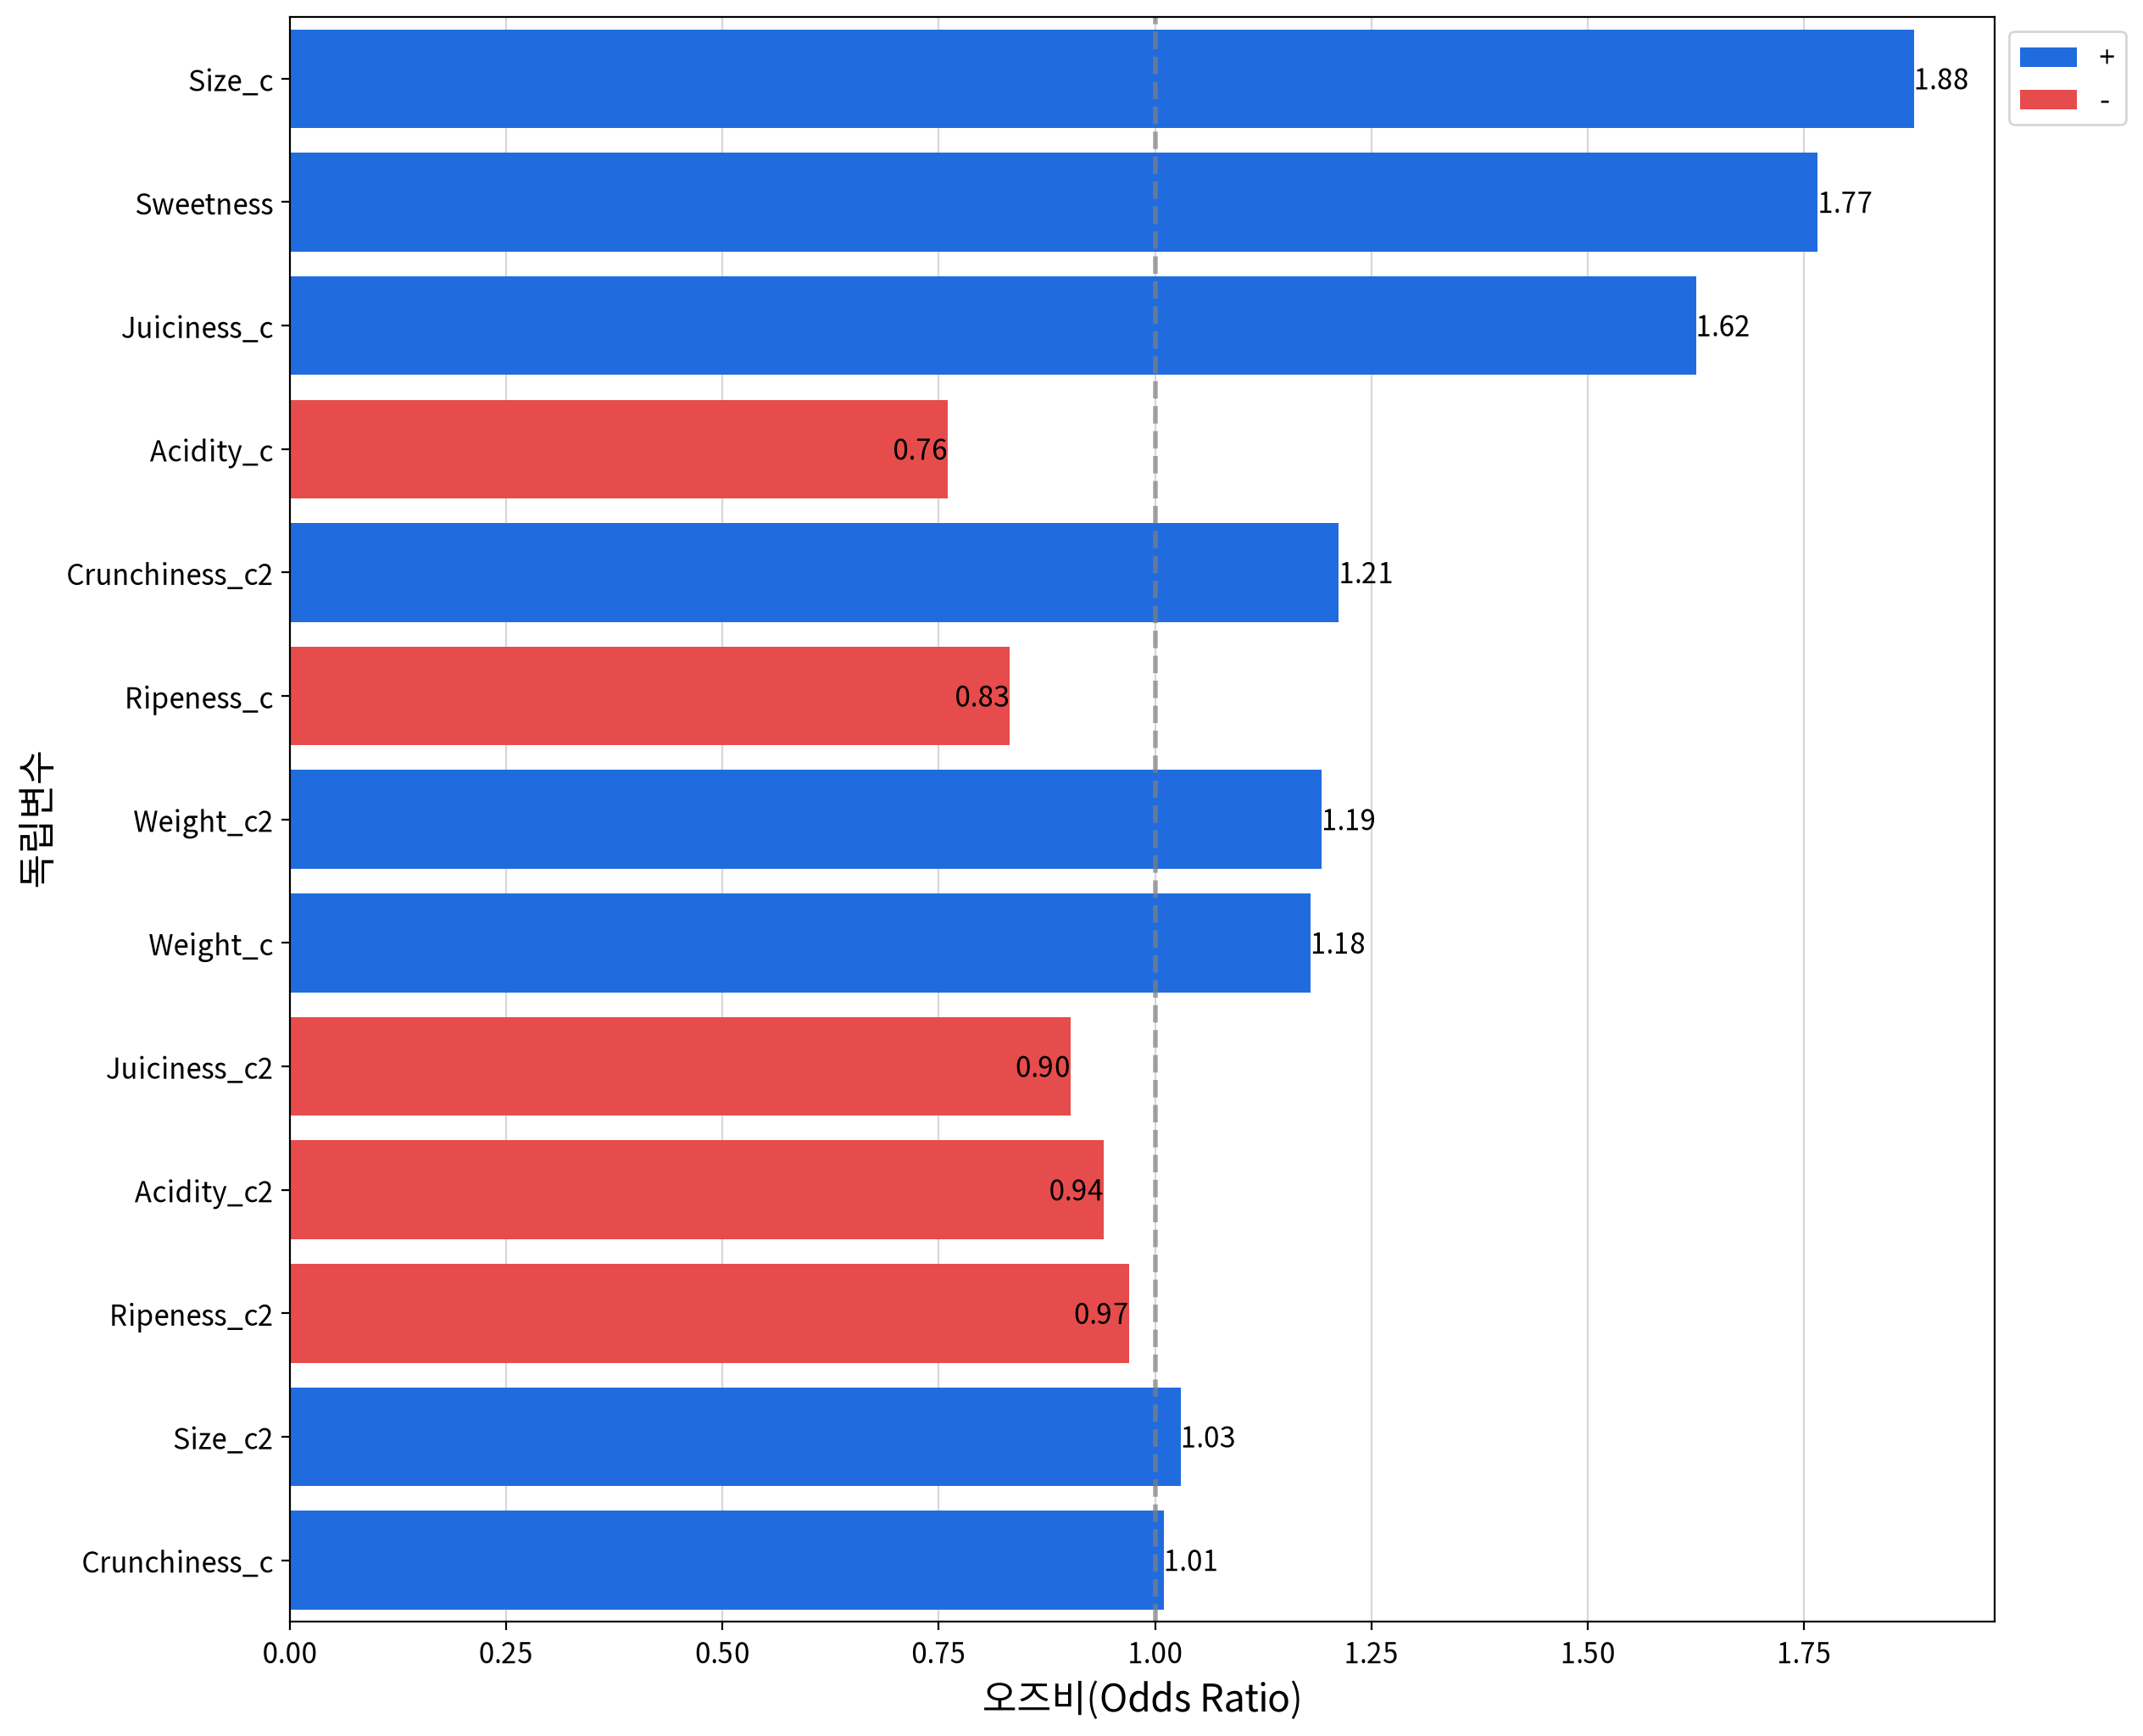

In [53]:
my_logit.auto_logit(data=final_data, y=target)

> ※ **오즈비(OR)의 크기로 변수의 영향력을 비교하면 안 된다.**
> 변수 간 값의 범위가 동일한 경우만 오즈비를 직접 비교할 수 있다.
> 값의 범위가 서로 다르면 범위를 통일한 **표준화 계수(β)** 로 영향력을 비교해야 한다.

> ##### 💡 인사이트 — 최종 모델
>
> **① 적합도**
> - **LLR χ²(13) = 1,899.19, p < .001, Pseudo R² = 0.342** — 로지스틱 회귀에서 Pseudo R²가 0.2~0.4면 매우 좋은 적합으로 본다.
>   - 즉, 독립변수 13개를 넣은 모델이 아무것도 넣지 않은 모델보다 유의하게 낫다.
> - 13개 항 중 12개가 유의하다. 유일하게 유의하지 않은 `Crunchiness_c`(1차항)는 계층 원칙에 따라 남겼다.
>
><br>
>
> **② 영향력 순위 (표준화 계수 β)**
> - **크기 · 단맛 · 과즙이 품질을 가르는 3대 축**이다.
>
> | 순위 | 변수 | β | 의미 |
> |---|---|---|---|
> | 1 | `Size` (1차항) | 1.214 | 클수록 `good` |
> | 2 | `Sweetness` | 1.105 | 달수록 `good` |
> | 3 | `Juiciness` (1차항) | 0.937 | 과즙이 많을수록 `good` |
>
><br>
>
> **③ 직선 관계 — 오즈비로 해석**
>
> | 변수 | 오즈비 | 해석 |
> |---|---|---|
> | `Sweetness` | 1.766 | 단맛 1점 ↑ → `good`일 오즈 **76.6% 증가** |
>
><br>
>
> **④ 곡선 관계 — 모양으로 해석**
> - 제곱항이 있는 변수는 1차항과 제곱항이 **함께** 곡선을 만들어서, 오즈비 하나로 해석하지 않는다.
> - 제곱항 B가 **양수면 ∪(아래로 볼록)**, **음수면 ∩(위로 볼록)** 이다.
> - 제곱항이 1차항보다 아주 작으면 곡선이 거의 휘지 않아 **직선에 가깝게** 읽는다.
>
> | 변수 | 1차항 B | 제곱항 B | 모양 | 해석 |
> |---|---|---|---|---|
> | `Size` | +0.629 | +0.029 | ∪(거의 직선) | 클수록 좋고, 커질수록 효과가 **조금씩 커진다** |
> | `Weight` | +0.165 | +0.176 | ∪ | 평균 근처가 가장 나쁘고, **양쪽으로 멀어질수록** 좋다 |
> | `Crunchiness` | +0.010 (n.s.) | +0.192 | ∪ | **아주 아삭하거나 아주 무른** 사과가 좋고, 중간이 나쁘다 |
> | `Juiciness` | +0.485 | −0.103 | ∩ | 많을수록 좋지만, **너무 많으면 오히려 나빠진다**(적당히 많은 게 가장 좋음) |
> | `Ripeness` | −0.184 | −0.031 | ∩ | 덜 익을수록 좋고, **많이 익을수록 더 빠르게 나빠진다** |
> | `Acidity` | −0.274 | −0.061 | ∩ | 산도가 높을수록 나쁘고, **높아질수록 더 빠르게 나빠진다** |
>
><br>
>
> **⑤ 가장 큰 반전 — `Crunchiness`**
> - T검정에서 p = 0.985(차이 없음), 기준선 모형에서 p = 0.253(제거 후보)이었던 변수가, **제곱항을 넣자 z = 10.40의 강한 예측 변수**가 됐다.
> - 이유는 관계가 **U자**이기 때문이다. 아주 아삭한 사과와 아주 무른 사과가 모두 `good` 쪽에 많고, 중간 정도가 `bad` 쪽에 많다.
>   - **T검정(평균 비교)** : `good` 집단에는 양 끝의 사과가 섞여 있어 평균이 중간으로 모이고, `bad` 집단의 평균과 같아진다.
>   - **기준선 모형(직선)** : 왼쪽에서도 오른쪽에서도 올라가는 U자를 직선 하나로 그으면, 기울기가 0에 가까운 평평한 선이 된다.
>   - **가정 검정(Box-Tidwell)** 만이 '직선이 아니다'를 잡아냈다. EDA와 기준선 모형만 봤다면 놓쳤을 변수다.

### (2) 분류 성능 평가

,예측 0 (Negative),예측 1 (Positive)
실제 0 (Negative),1555,441
실제 1 (Positive),392,1612


,정확도(Accuracy),정밀도(Precision),"재현율(Recall,TPR)","위양성율(Fallout,FPR)","특이성(Specificity,TNR)",F1,AUC,AUC 판단,진단오즈비(DOR)
performance,0.792,0.785,0.804,0.221,0.779,0.795,0.868,판별력 우수,14.500


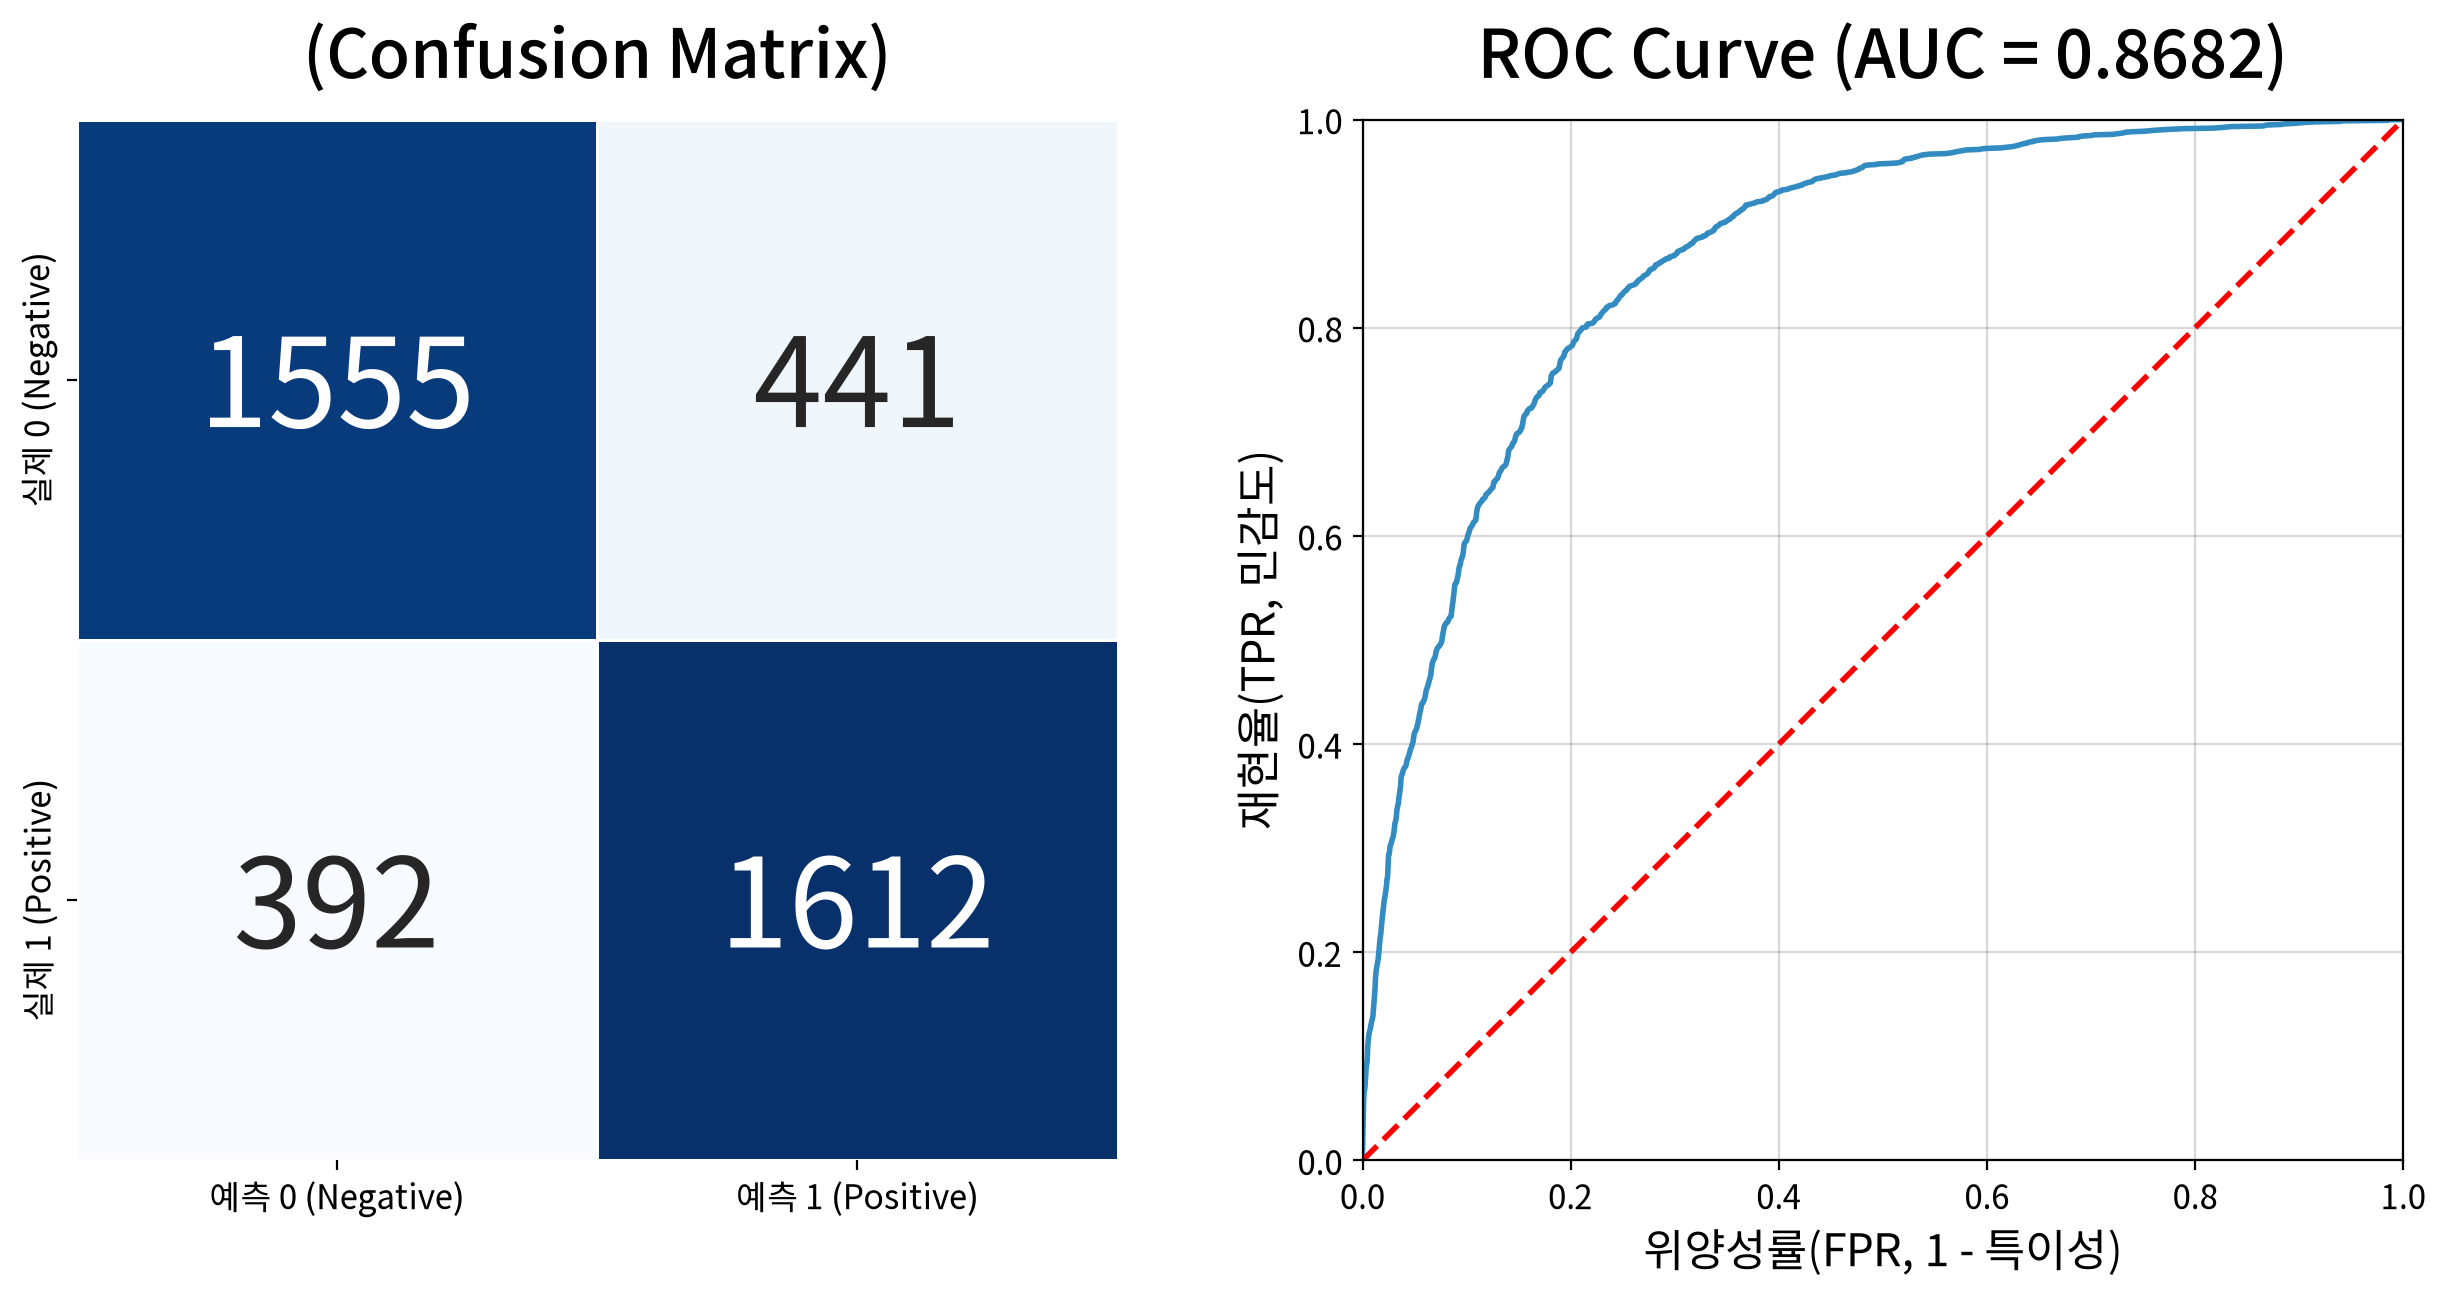

In [54]:
my_logit.report_performance(final_fit)

>##### 💡 인사이트
>
>| 지표 | 값 | 의미 |
>|---|---|---|
>| 정확도 | 0.792 | 4,000개 중 3,167개를 맞혔다. 게으른 모델의 바닥값(50.1%)보다 **29%p 높다** |
>| 정밀도 | 0.785 | `good`으로 판정한 사과 중 78.5%가 실제 `good` |
>| 재현율 | 0.804 | 실제 `good` 사과 2,004개 중 1,612개(80.4%)를 찾아냈다 |
>| 위양성률 | 0.221 | `bad` 사과의 22.1%를 `good`으로 잘못 판정했다 (= 1 − 특이성) |
>| 특이성 | 0.779 | `bad` 사과의 77.9%를 `bad`로 맞혔다 |
>| F1 | 0.795 | 정밀도와 재현율을 합친 점수. 정확도(0.792)와 **거의 같다** → 두 집단을 고르게 맞힌다 |
>| AUC | 0.868 | `good` 사과 하나와 `bad` 사과 하나를 무작위로 뽑았을 때, 모델이 `good` 쪽에 더 높은 확률을 줄 가능성 **86.8% (우수)** |
>| 진단 오즈비 | 14.50 | `good`으로 판정한 사과가 실제 `good`일 오즈가, `bad`로 판정한 사과의 **약 14.5배** |
>
>- **정밀도 · 재현율 · 특이성이 모두 0.78~0.80으로 고르고, F1이 정확도와 거의 같다.** 두 집단의 크기가 거의 같은 균형 데이터이기 때문이다.

### (3) 임계값 조정

- 임계값 0.5는 관례일 뿐 **정답이 아니다.** 목적에 따라 조정한다.
- 표의 `FN`은 실제 `good`인데 `bad`로 판정한 사과(놓친 good), `FP`는 실제 `bad`인데 `good`으로 판정한 사과(잘못 통과시킨 bad)다.

In [55]:
my_logit.report_threshold(final_fit)

,정확도,정밀도,재현율,F1,FN (놓침 : 실제1→예측0),FP (헛짚음 : 실제0→예측1)
임계값,,,,,,
0.300,0.765,0.699,0.932,0.799,137,803
0.400,0.784,0.740,0.875,0.802,250,615
0.500,0.792,0.785,0.804,0.795,392,441
0.600,0.779,0.822,0.713,0.764,575,309
0.700,0.747,0.857,0.594,0.702,813,198


> ##### 💡 인사이트 — 임계값은 목적이 정한다
>
> | 임계값 | 정확도 | 정밀도 | 재현율 | F1 | 버려진 `good` (FN) | 통과한 `bad` (FP) |
> |---|---|---|---|---|---|---|
> | 0.3 | 0.765 | 0.699 | **0.932** | 0.799 | **137개** | 803개 |
> | 0.4 | 0.784 | 0.740 | 0.875 | **0.802** | 250개 | 615개 |
> | 0.5 (기본) | **0.792** | 0.785 | 0.804 | 0.795 | 392개 | 441개 |
> | 0.6 | 0.779 | 0.822 | 0.713 | 0.764 | 575개 | 309개 |
> | 0.7 | 0.747 | **0.857** | 0.594 | 0.702 | 813개 | **198개** |
>
> - **정확도는 0.5에서 최대(0.792)** 지만, **F1은 0.4에서 최대(0.802)** 다.
> - **트레이드오프가 그대로 나타난다.** 
>   - 임계값 0.3 → 재현율 0.932 / 정밀도 0.699
>   - 임계값 0.7 → 정밀도 0.857 / 재현율 0.594
> - **정답은 목적이 정한다.**
>   - **프리미엄 등급 선별**(내보내는 사과는 반드시 `good`이어야 함) → 임계값 **0.7** : 통과한 `bad`가 441개 → 198개로 절반 이하, 정밀도 0.857
>   - **폐기 판정**(좋은 사과를 버리면 손해) → 임계값 **0.3** : 버려지는 `good`이 392개 → 137개로 3분의 1, 재현율 0.932

---

# 📌 종합 인사이트

### 1. 품질을 가르는 3대 축은 크기 · 단맛 · 과즙
- 표준화 계수 β 기준 **`Size`(1.214) > `Sweetness`(1.105) > `Juiciness`(0.937)** 다.
- 산도와 숙성도는 높을수록 품질에 불리하다.

### 2. EDA에서 '무관'이던 변수가 모델에서 살아났다
- `Weight` · `Acidity`는 단독 비교(T검정)에서 차이가 없었지만, 다른 변수를 통제하자 **강하게 유의**해졌다(억제효과).
- `Crunchiness`는 단독 비교와 직선 모형 모두에서 무관했지만, **U자 곡선**이라는 것이 드러나자 강한 예측 변수가 됐다.
- → **EDA에서 유의하지 않다는 이유만으로 변수를 버리면 안 된다.**

### 3. 성능을 올린 것은 전처리가 아니라 가정 검정이었다

| 계열 | AUC | 정확도 |
|---|---|---|
| 직선 가정 (기준선 · 후진소거 · 이상치 대체 · 정규화) | 0.823 ~ 0.824 | 0.749 ~ 0.750 |
| **로짓 선형성 처방 반영 (제곱항)** | **0.868** | **0.792** |

- 이상치 대체 · 정규화는 성능을 거의 바꾸지 못했다. **모형의 구조(직선 vs 곡선)를 바로잡은 것**이 결정적이었다.

### 4. 자동 선택 결과는 분석자가 검토해야 한다
- `compare_models()`가 고른 5번 모델은 제곱항의 짝인 1차항을 지워 계층 원칙을 어겼다. AIC 차이가 1.93에 불과해 **4번(두 항 모두 유지)을 최종 채택**했다.

### 5. 임계값은 목적이 정한다
- 정확도는 임계값 0.5에서 최대(0.792), F1은 0.4에서 최대(0.802)다.
- **프리미엄 선별**(통과시킨 사과는 반드시 `good`) → 임계값을 높여 정밀도 확보, **폐기 판정**(좋은 사과를 버리면 손해) → 임계값을 낮춰 재현율 확보.

### ⚠️ 한계
- **처방 선택이 자동 규칙에 의존한다.** 7종 모두 음수를 포함해 로그 변환이 후보에서 빠졌으므로, 사실상 제곱항 외의 선택지가 없었다. 실제로는 로짓 대비 산점도의 모양을 함께 보고 판단하는 것이 원칙이다.
- **모형이 복잡해졌다.** 제곱항 6개를 추가하면서 변수당 계수가 2개가 되어 오즈비를 한 줄로 해석할 수 없고, 과적합 위험도 올라갔다.
- **성능을 학습 데이터에서 측정했다(in-sample).** 정확도 0.792 · AUC 0.868은 낙관적인 값이며, train/test 분할이나 교차검증으로 확인해야 한다.
- **변수의 물리적 의미를 알 수 없다.** 값이 표준화된 점수로 제공되어 '크기 1점'이 몇 mm인지, '산도 1점'이 pH 얼마인지 알 수 없다.
- **품질 라벨의 기준이 공개되어 있지 않다.** 모형이 학습한 것은 '사과의 객관적 품질'이 아니라 '이 데이터를 만든 사람의 판정 기준'일 수 있다.
- **인과관계가 아니라 연관관계다.** 산도를 인위적으로 낮춘다고 사과가 `good`이 되지는 않는다.

### ✅ 최종 모델

| 항목 | 값 |
|---|---|
| 모델 | `4_가정반영` |
| 형태 | `logit(P(good))` ~ `Sweetness` + 6개 변수의 1차항 · 제곱항 (13개 항) |
| 성능 | 정확도 0.792 · AUC 0.868 · Pseudo R² 0.342 |
| 가장 큰 영향 | `Size` (β = 1.214) |